# Lab 5: Reconstructed Dynamics and State Transitions

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)

This study asks whether the three time series from Lab 1 admit useful reconstructed state spaces. Delay and embedding dimension are estimated from the data, the resulting trajectories are inspected locally with t-SNE, and recurrent regimes are summarized as directed transition graphs. The same reconstruction is then given to the Lab 4 LSTM, with initialization seeds matched for each test block, to compare the two input representations.


In [1]:
import sys
import subprocess
import importlib.util
from pathlib import Path

LAB_DIR = Path.cwd()
if not (LAB_DIR / "M5_Lopatenko.ipynb").exists():
    candidates = [LAB_DIR / "tsml" / "lab-5", LAB_DIR.parent / "tsml" / "lab-5", Path("/content")]
    for candidate in candidates:
        if (candidate / "M5_Lopatenko.ipynb").exists():
            LAB_DIR = candidate
            break

REQUIRED_MODULES = ["numpy", "pandas", "scipy", "sklearn", "torch", "plotly", "kaleido", "prettytable", "igraph"]
missing = [
    "scikit-learn" if module == "sklearn" else module
    for module in REQUIRED_MODULES
    if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [2]:
import base64
import copy
import html
import json
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from urllib.request import Request, urlopen

import igraph as ig
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import torch
from IPython.display import HTML, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import cdist
from sklearn.feature_selection import mutual_info_regression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from torch import nn

warnings.filterwarnings("ignore")

SEED = 42
HORIZONS = (1, 7, 14)
N_SPLITS = 10
MAX_DIMENSION = 10
DEVELOPMENT_TAIL = N_SPLITS * max(HORIZONS)
MAX_TRAIN_WINDOWS = 384
VALIDATION_SHARE = 0.15
MAX_EPOCHS = 80
PATIENCE = 8
FIG_WIDTH, FIG_SCALE = 1320, 3

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
pio.templates.default = "plotly_white"

DATA_DIR = LAB_DIR / "data"
FIGURES_DIR = LAB_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SERIES_COLORS = {
    "EU_Hourly_Load": "#0072B2",
    "ECG_TF_Normal": "#009E73",
    "SPY_AdjClose": "#CC79A7",
}
STATE_COLORS = ["#440154", "#472D7B", "#3B528B", "#2C728E", "#21918C", "#27AD81", "#5CC863", "#8FD744"]
STATE_TEXT_COLORS = ["#FFFFFF", "#FFFFFF", "#FFFFFF", "#FFFFFF", "#111111", "#111111", "#111111", "#111111"]
STATE_SYMBOLS = ["circle", "square", "diamond", "triangle-up", "triangle-down", "pentagon", "hexagon", "star"]
METHOD_COLORS = {"Lab 4 LSTM": "#4477AA", "Embedding-aware LSTM": "#EE6677"}


def show_table(frame: pd.DataFrame, caption: str, precision: int = 4, max_width: int = 28) -> None:
    def fmt(value) -> str:
        if pd.isna(value):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{precision}f}"
        return str(value)

    table = PrettyTable()
    table.title = caption
    table.field_names = [str(column) for column in frame.columns]
    table.align = "l"
    for field in table.field_names:
        table.max_width[field] = max_width
    for row in frame.itertuples(index=False, name=None):
        table.add_row([fmt(value) for value in row])
    print(table)


def show_and_save(
    fig: go.Figure,
    stem: str,
    alt_text: str,
    height: int = 780,
    top_margin: int = 125,
    bottom_margin: int = 110,
    legend_y: float = 1.02,
) -> None:
    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=height,
        margin=dict(l=75, r=45, t=top_margin, b=bottom_margin),
        title_y=0.985,
        title_yanchor="top",
        font=dict(size=18, color="#252525"),
        legend=dict(
            orientation="h", yanchor="bottom", y=legend_y, xanchor="left", x=0,
            bgcolor="rgba(255,255,255,0.92)", bordercolor="#d1d5db", borderwidth=1,
        ),
    )
    for annotation in fig.layout.annotations:
        if annotation.font is None or annotation.font.size is None or annotation.font.size < 17:
            annotation.font = dict(size=17, color="#252525")
    png_path = FIGURES_DIR / f"{stem}.png"
    svg_path = FIGURES_DIR / f"{stem}.svg"
    fig.write_image(str(png_path), scale=FIG_SCALE, width=FIG_WIDTH, height=height)
    fig.write_image(str(svg_path), width=FIG_WIDTH, height=height)
    encoded = base64.b64encode(png_path.read_bytes()).decode("ascii")
    display(HTML(
        f'<img src="data:image/png;base64,{encoded}" alt="{html.escape(alt_text)}" '
        'style="max-width:100%;height:auto;">'
    ))


## 1. Three series, three kinds of dynamics

### EU hourly electricity load

The final 720 hourly observations cover 30 days. The signal is governed by a strong day–night rhythm, a weaker weekly calendar effect and changing peak demand. A reconstructed state should therefore separate hours that have similar current load but different positions in the daily cycle.

### Normal ECG

Six normal 140-sample beats from the TensorFlow ECG dataset are concatenated into an 840-point signal. The repeated P–QRS–T morphology gives a clear closed-loop intuition, but the boundaries join separately segmented beats. Those joins are preprocessing artifacts rather than physiological transitions and remain visible in the interpretation.

### SPY adjusted close

The final 750 daily adjusted closing prices form a persistent, non-stationary level series. Nearby prices naturally occupy nearby locations in phase space even when returns are difficult to forecast. A smooth reconstruction here is evidence of persistence, not by itself evidence of deterministic low-dimensional market dynamics.


In [3]:
@dataclass(frozen=True)
class SeriesData:
    key: str
    label: str
    values: np.ndarray
    index: np.ndarray
    unit: str
    source: str


ENERGY_URL = "https://raw.githubusercontent.com/unit8co/darts/master/datasets/energy_dataset.csv"
ECG_URL = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"


def download(url: str, destination: Path) -> Path:
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=120) as response, destination.open("wb") as output:
        output.write(response.read())
    return destination


def local_or_download(filename: str, url: str, alternatives: list[Path]) -> Path:
    for path in [DATA_DIR / filename, *alternatives]:
        if path.exists() and path.stat().st_size > 0:
            return path
    return download(url, DATA_DIR / filename)


def load_energy(n: int = 720) -> SeriesData:
    path = local_or_download(
        "energy_dataset.csv", ENERGY_URL,
        [
            LAB_DIR.parent / "lab-2" / "data" / "energy_dataset.csv",
            LAB_DIR.parent / "lab-1" / "data" / "energy_dataset.csv",
        ],
    )
    frame = pd.read_csv(path).dropna(subset=["total load actual"]).iloc[-n:]
    time_column = "time" if "time" in frame.columns else frame.columns[0]
    return SeriesData(
        "EU_Hourly_Load", "EU hourly load", frame["total load actual"].to_numpy(dtype=float),
        pd.to_datetime(frame[time_column], utc=True, errors="coerce").to_numpy(), "MW",
        "Darts energy_dataset.csv; ENTSO-E total load actual",
    )


def load_ecg(n_beats: int = 6) -> SeriesData:
    path = local_or_download(
        "ecg.csv", ECG_URL,
        [LAB_DIR.parent / "lab-2" / "data" / "ecg.csv", LAB_DIR.parent / "lab-1" / "data" / "ecg.csv"],
    )
    frame = pd.read_csv(path, header=None)
    values = frame[frame.iloc[:, -1] == 1].iloc[:n_beats, :-1].to_numpy(dtype=float).ravel()
    return SeriesData(
        "ECG_TF_Normal", "Normal ECG", values, np.arange(len(values)), "normalized amplitude",
        "TensorFlow ECG anomaly dataset; six normal beats",
    )


def load_spy(n: int = 750) -> SeriesData:
    candidates = [
        DATA_DIR / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-2" / "data" / "SPY_AdjClose.csv",
        LAB_DIR.parent / "lab-1" / "data" / "SPY_AdjClose.csv",
    ]
    for path in candidates:
        if path.exists() and path.stat().st_size > 0:
            frame = pd.read_csv(path, parse_dates=["Date"])
            price_column = "SPY" if "SPY" in frame.columns else "Adj Close"
            if price_column not in frame.columns:
                price_column = "Close"
            frame = frame[["Date", price_column]].dropna().iloc[-n:]
            return SeriesData(
                "SPY_AdjClose", "SPY adjusted close", frame[price_column].to_numpy(dtype=float),
                pd.DatetimeIndex(frame["Date"]).to_pydatetime(), "USD",
                "Yahoo Finance adjusted daily close",
            )

    url = "https://query1.finance.yahoo.com/v8/finance/chart/SPY?interval=1d&range=5y"
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        payload = json.loads(response.read().decode("utf-8"))
    result = payload["chart"]["result"][0]
    frame = pd.DataFrame({
        "Date": pd.to_datetime(result["timestamp"], unit="s"),
        "Adj Close": result["indicators"]["adjclose"][0]["adjclose"],
    }).dropna().iloc[-n:]
    frame.to_csv(DATA_DIR / "SPY_AdjClose.csv", index=False)
    return SeriesData(
        "SPY_AdjClose", "SPY adjusted close", frame["Adj Close"].to_numpy(dtype=float),
        pd.DatetimeIndex(frame["Date"]).to_pydatetime(), "USD",
        "Yahoo Finance adjusted daily close",
    )


series = {item.key: item for item in [load_energy(), load_ecg(), load_spy()]}


The reconstruction is applied to the same three Lab 1 series:

| Series | Observations | Sampling | Structure relevant here |
|:--|--:|:--|:--|
| EU hourly load | 720 | Hourly | 24-hour and weekly demand rhythms |
| Normal ECG | 840 | Samples within six beats | Six repeated 140-sample morphologies |
| SPY adjusted close | 750 | Trading days | Persistent, non-stationary price level |



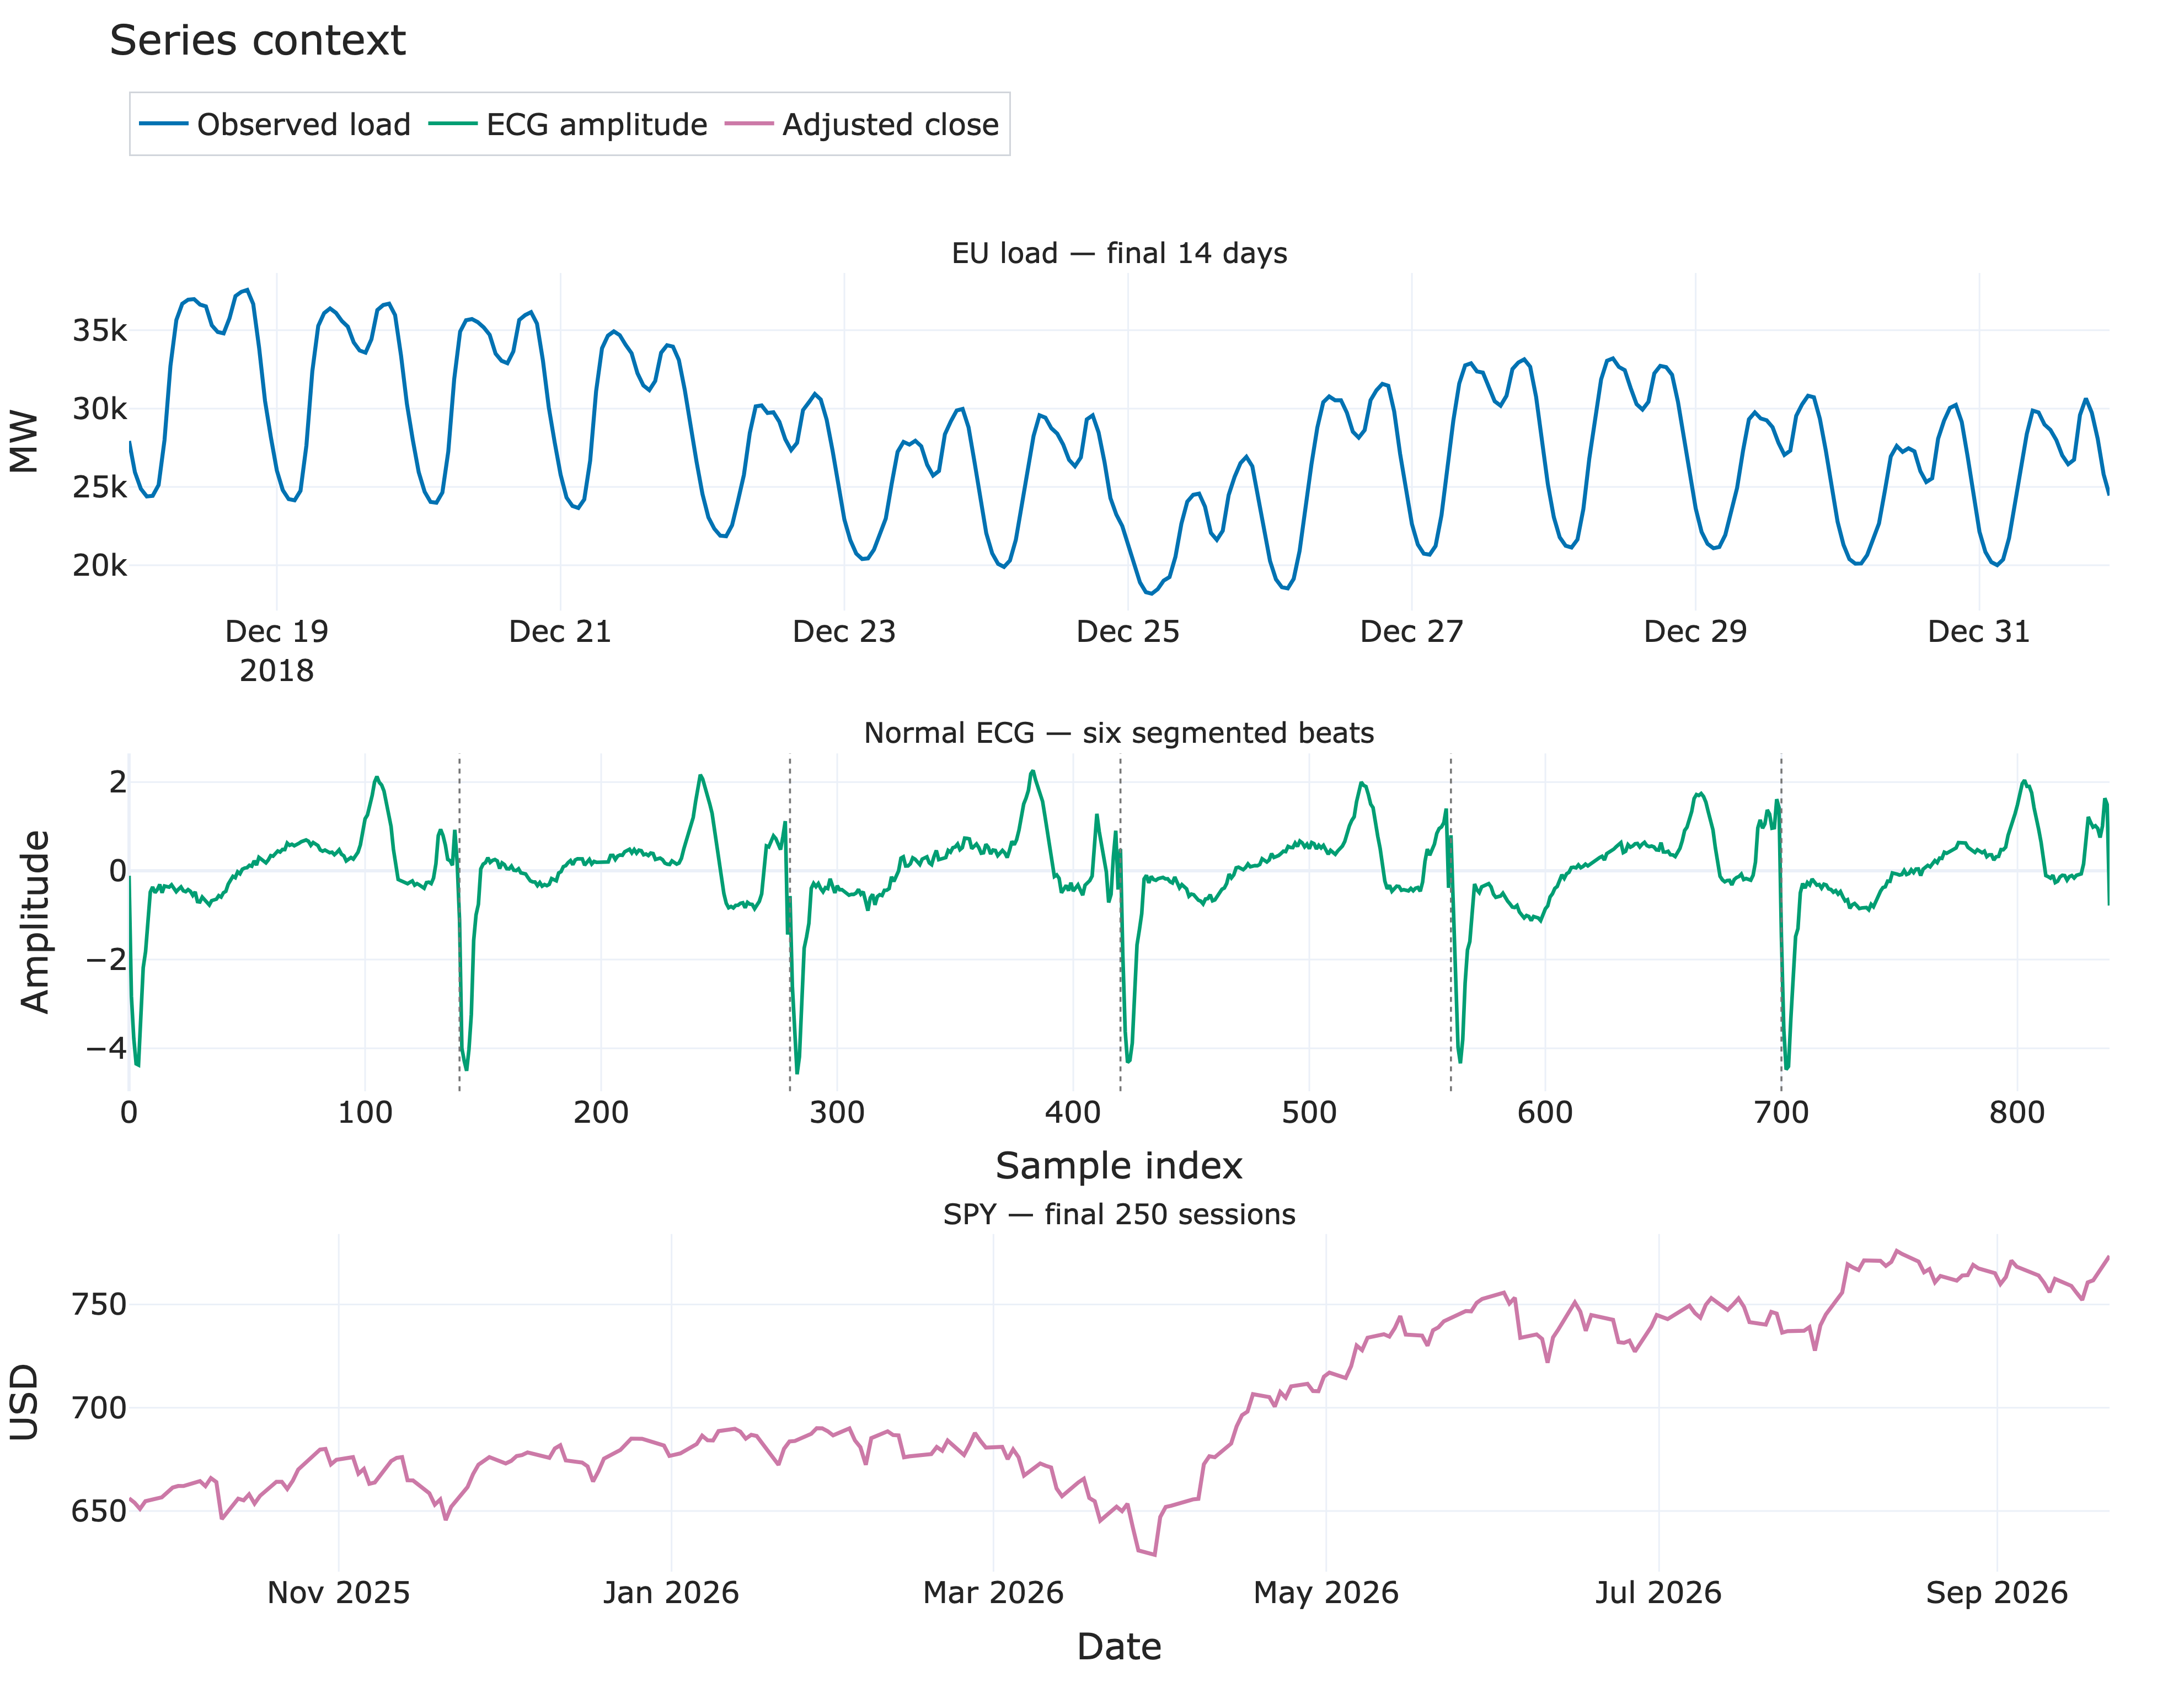

In [4]:
fig = make_subplots(
    rows=3,
    cols=1,
    vertical_spacing=0.11,
    subplot_titles=(
        "EU load — final 14 days",
        "Normal ECG — six segmented beats",
        "SPY — final 250 sessions",
    ),
)

load = series["EU_Hourly_Load"]
fig.add_trace(
    go.Scatter(
        x=load.index[-24 * 14:],
        y=load.values[-24 * 14:],
        mode="lines",
        name="Observed load",
        line=dict(color=SERIES_COLORS[load.key], width=2.4),
    ),
    row=1,
    col=1,
)

ecg = series["ECG_TF_Normal"]
fig.add_trace(
    go.Scatter(
        x=ecg.index,
        y=ecg.values,
        mode="lines",
        name="ECG amplitude",
        line=dict(color=SERIES_COLORS[ecg.key], width=2.2),
    ),
    row=2,
    col=1,
)
for boundary in range(140, len(ecg.values), 140):
    fig.add_vline(x=boundary, line_width=1.2, line_dash="dot", line_color="#777777", row=2, col=1)

spy = series["SPY_AdjClose"]
fig.add_trace(
    go.Scatter(
        x=spy.index[-250:],
        y=spy.values[-250:],
        mode="lines",
        name="Adjusted close",
        line=dict(color=SERIES_COLORS[spy.key], width=2.4),
    ),
    row=3,
    col=1,
)

fig.update_yaxes(title_text="MW", row=1, col=1)
fig.update_yaxes(title_text="Amplitude", row=2, col=1)
fig.update_yaxes(title_text="USD", row=3, col=1)
fig.update_xaxes(title_text="Sample index", row=2, col=1)
fig.update_xaxes(title_text="Date", row=3, col=1)
fig.update_layout(title="Series context", hovermode="x unified")
show_and_save(
    fig, "series_context",
    "Hourly load, normal ECG, and SPY adjusted-close overview",
    height=1030, top_margin=165, bottom_margin=80, legend_y=1.09,
)


Data sources: Darts/ENTSO-E energy data, TensorFlow ECG anomaly data, and Yahoo Finance adjusted close.

The load and ECG panels contain visibly repeated geometry, but for different reasons: load follows an external calendar, while the ECG rows repeat a standardized morphology. SPY instead drifts through level space. These differences matter because delay reconstruction can organize any persistent sequence; only additional diagnostics can tell us whether the reconstruction is compact and stable enough to interpret.

## 2. Delay, embedding dimension and correlation dimension

A delay vector at time $t$ is

$$\mathbf{x}_t=[x_t,x_{t-\tau},\ldots,x_{t-(m-1)\tau}].$$

The delay $\tau$ is the first local minimum of average mutual information (AMI), where available. AMI detects nonlinear as well as linear dependence: a useful delay should separate coordinates enough to add information without making them unrelated. If AMI has no interior minimum, $\tau=1$ is retained, indicating that the sample does not reveal a distinct decorrelation scale.

The embedding dimension $m$ is the first dimension with fewer than 5% false nearest neighbours (FNN). A neighbour is false when adding the next delayed coordinate increases its distance by an implausibly large factor. Points within one delay of each other are excluded from the neighbour search; otherwise consecutive samples would make the result look artificially low-dimensional.

The two standard FNN checks are used: the added-coordinate distance must not exceed ten times the previous neighbour distance, and the expanded distance must not exceed twice the standard deviation of the series. The delay and embedding dimension used for forecasting are estimated on the prefix ending before the earliest 14-step test block. The phase portraits later describe the full sample, but they do not change those choices.

The correlation dimension $D_2$ is estimated from the slope of $\log C(r)$ against $\log r$, where $C(r)$ is the fraction of temporally separated pairs closer than radius $r$. The fit uses the intermediate region $0.02\leq C(r)\leq0.30$: very small radii are sparse and very large radii are dominated by the finite diameter of the cloud. The reported $R^2$ describes linearity over this chosen scaling interval; neither a high $R^2$ nor a finite slope alone proves deterministic chaos.


In [5]:
def standardize(values: np.ndarray) -> np.ndarray:
    scale = float(np.std(values))
    return (np.asarray(values, dtype=float) - np.mean(values)) / (scale if scale > 1e-12 else 1.0)


def delay_embedding(values: np.ndarray, dimension: int, delay: int) -> tuple[np.ndarray, np.ndarray]:
    times = np.arange((dimension - 1) * delay, len(values))
    embedded = np.column_stack([values[times - lag * delay] for lag in range(dimension)])
    return embedded, times


def ami_curve(values: np.ndarray, max_lag: int, seed: int = SEED) -> tuple[np.ndarray, np.ndarray]:
    normalized = standardize(values)
    lags = np.arange(1, max_lag + 1)
    ami = np.array([
        mutual_info_regression(
            normalized[:-lag].reshape(-1, 1), normalized[lag:],
            n_neighbors=5, random_state=seed,
        )[0]
        for lag in lags
    ])
    return lags, ami


def select_delay(lags: np.ndarray, ami: np.ndarray) -> tuple[int, str]:
    for index in range(1, len(ami) - 1):
        if ami[index] < ami[index - 1] and ami[index] <= ami[index + 1]:
            return int(lags[index]), "first AMI minimum"
    return 1, "no AMI minimum; one-step fallback"


def false_nearest_curve(values: np.ndarray, delay: int, max_dimension: int = MAX_DIMENSION) -> np.ndarray:
    z = standardize(values)
    fractions = []
    theiler = max(1, delay)
    for dimension in range(1, max_dimension + 1):
        times = np.arange(dimension * delay, len(z))
        current = np.column_stack([z[times - lag * delay] for lag in range(dimension)])
        distances = cdist(current, current)
        temporal = np.abs(times[:, None] - times[None, :]) <= theiler
        distances[temporal] = np.inf
        neighbour = np.argmin(distances, axis=1)
        base_distance = distances[np.arange(len(times)), neighbour]
        added_difference = np.abs(z[times - dimension * delay] - z[times[neighbour] - dimension * delay])
        expanded_distance = np.sqrt(base_distance ** 2 + added_difference ** 2)
        false = (added_difference / np.maximum(base_distance, 1e-12) > 10) | (expanded_distance > 2.0)
        fractions.append(100 * np.mean(false))
    return np.asarray(fractions)


def select_dimension(fnn: np.ndarray, threshold: float = 5.0) -> tuple[int, str]:
    acceptable = np.flatnonzero(fnn < threshold)
    if len(acceptable):
        return int(acceptable[0] + 1), "FNN below 5%"
    return int(len(fnn)), "10-D cap; FNN criterion not reached"


def correlation_dimension(values: np.ndarray, dimension: int, delay: int) -> dict:
    embedded, times = delay_embedding(standardize(values), dimension, delay)
    distances = cdist(embedded, embedded)
    upper = np.triu_indices(len(embedded), k=1)
    separated = np.abs(times[upper[0]] - times[upper[1]]) > max(1, delay)
    pair_distances = distances[upper][separated]
    positive = pair_distances[pair_distances > 0]
    lower, upper_radius = np.quantile(positive, [0.005, 0.55])
    radii = np.geomspace(lower, upper_radius, 32)
    correlation_sum = np.array([np.mean(pair_distances < radius) for radius in radii])
    scaling = (correlation_sum >= 0.02) & (correlation_sum <= 0.30)
    if scaling.sum() < 6:
        candidates = np.flatnonzero((correlation_sum > 0) & (correlation_sum < 1))
        scaling = np.zeros_like(correlation_sum, dtype=bool)
        scaling[candidates[len(candidates) // 4:3 * len(candidates) // 4]] = True
    log_r = np.log(radii)
    log_c = np.log(np.maximum(correlation_sum, 1e-12))
    slope, intercept = np.polyfit(log_r[scaling], log_c[scaling], 1)
    fitted = slope * log_r[scaling] + intercept
    return {
        "dimension": float(slope),
        "r2": float(r2_score(log_c[scaling], fitted)),
        "radii": radii,
        "correlation_sum": correlation_sum,
        "scaling": scaling,
        "intercept": float(intercept),
    }


max_lags = {"EU_Hourly_Load": 48, "ECG_TF_Normal": 70, "SPY_AdjClose": 40}
dimension_diagnostics = {}
dimension_rows = []

for key, item in series.items():
    development_values = item.values[:-DEVELOPMENT_TAIL]
    lags, ami = ami_curve(development_values, max_lags[key])
    delay, delay_rule = select_delay(lags, ami)
    fnn = false_nearest_curve(development_values, delay)
    dimension, dimension_rule = select_dimension(fnn)
    corr_by_m = [correlation_dimension(development_values, m, delay) for m in range(1, MAX_DIMENSION + 1)]
    corr = corr_by_m[dimension - 1]
    dimension_diagnostics[key] = {
        "lags": lags, "ami": ami, "delay": delay, "delay_rule": delay_rule,
        "fnn": fnn, "dimension": dimension, "dimension_rule": dimension_rule,
        "corr_by_m": corr_by_m, "corr": corr,
    }
    dimension_rows.append({
        "Series": item.label,
        "Development n": len(development_values),
        "Delay τ": delay,
        "Delay selection": delay_rule,
        "Embedding m": dimension,
        "FNN at m, %": fnn[dimension - 1],
        "Dimension selection": dimension_rule,
        "Correlation D₂": corr["dimension"],
        "Scaling R²": corr["r2"],
    })

dimension_summary = pd.DataFrame(dimension_rows)
dimension_summary.to_csv(LAB_DIR / "embedding_summary.csv", index=False)
show_table(
    dimension_summary[
        [
            "Series",
            "Development n",
            "Delay τ",
            "Delay selection",
            "Embedding m",
            "FNN at m, %",
            "Dimension selection",
        ]
    ],
    "Delay and embedding-dimension estimates", precision=3, max_width=31,
)
show_table(
    dimension_summary[["Series", "Correlation D₂", "Scaling R²"]],
    "Correlation-dimension estimates at the selected embedding", precision=3, max_width=34,
)


+--------------------------------------------------------------------------------------------------------------------+
|                                      Delay and embedding-dimension estimates                                       |
+--------------------+---------------+---------+-------------------+-------------+-------------+---------------------+
| Series             | Development n | Delay τ | Delay selection   | Embedding m | FNN at m, % | Dimension selection |
+--------------------+---------------+---------+-------------------+-------------+-------------+---------------------+
| EU hourly load     | 580           | 6       | first AMI minimum | 4           | 1.978       | FNN below 5%        |
| Normal ECG         | 700           | 9       | first AMI minimum | 4           | 2.861       | FNN below 5%        |
| SPY adjusted close | 610           | 7       | first AMI minimum | 3           | 4.075       | FNN below 5%        |
+--------------------+---------------+---------+


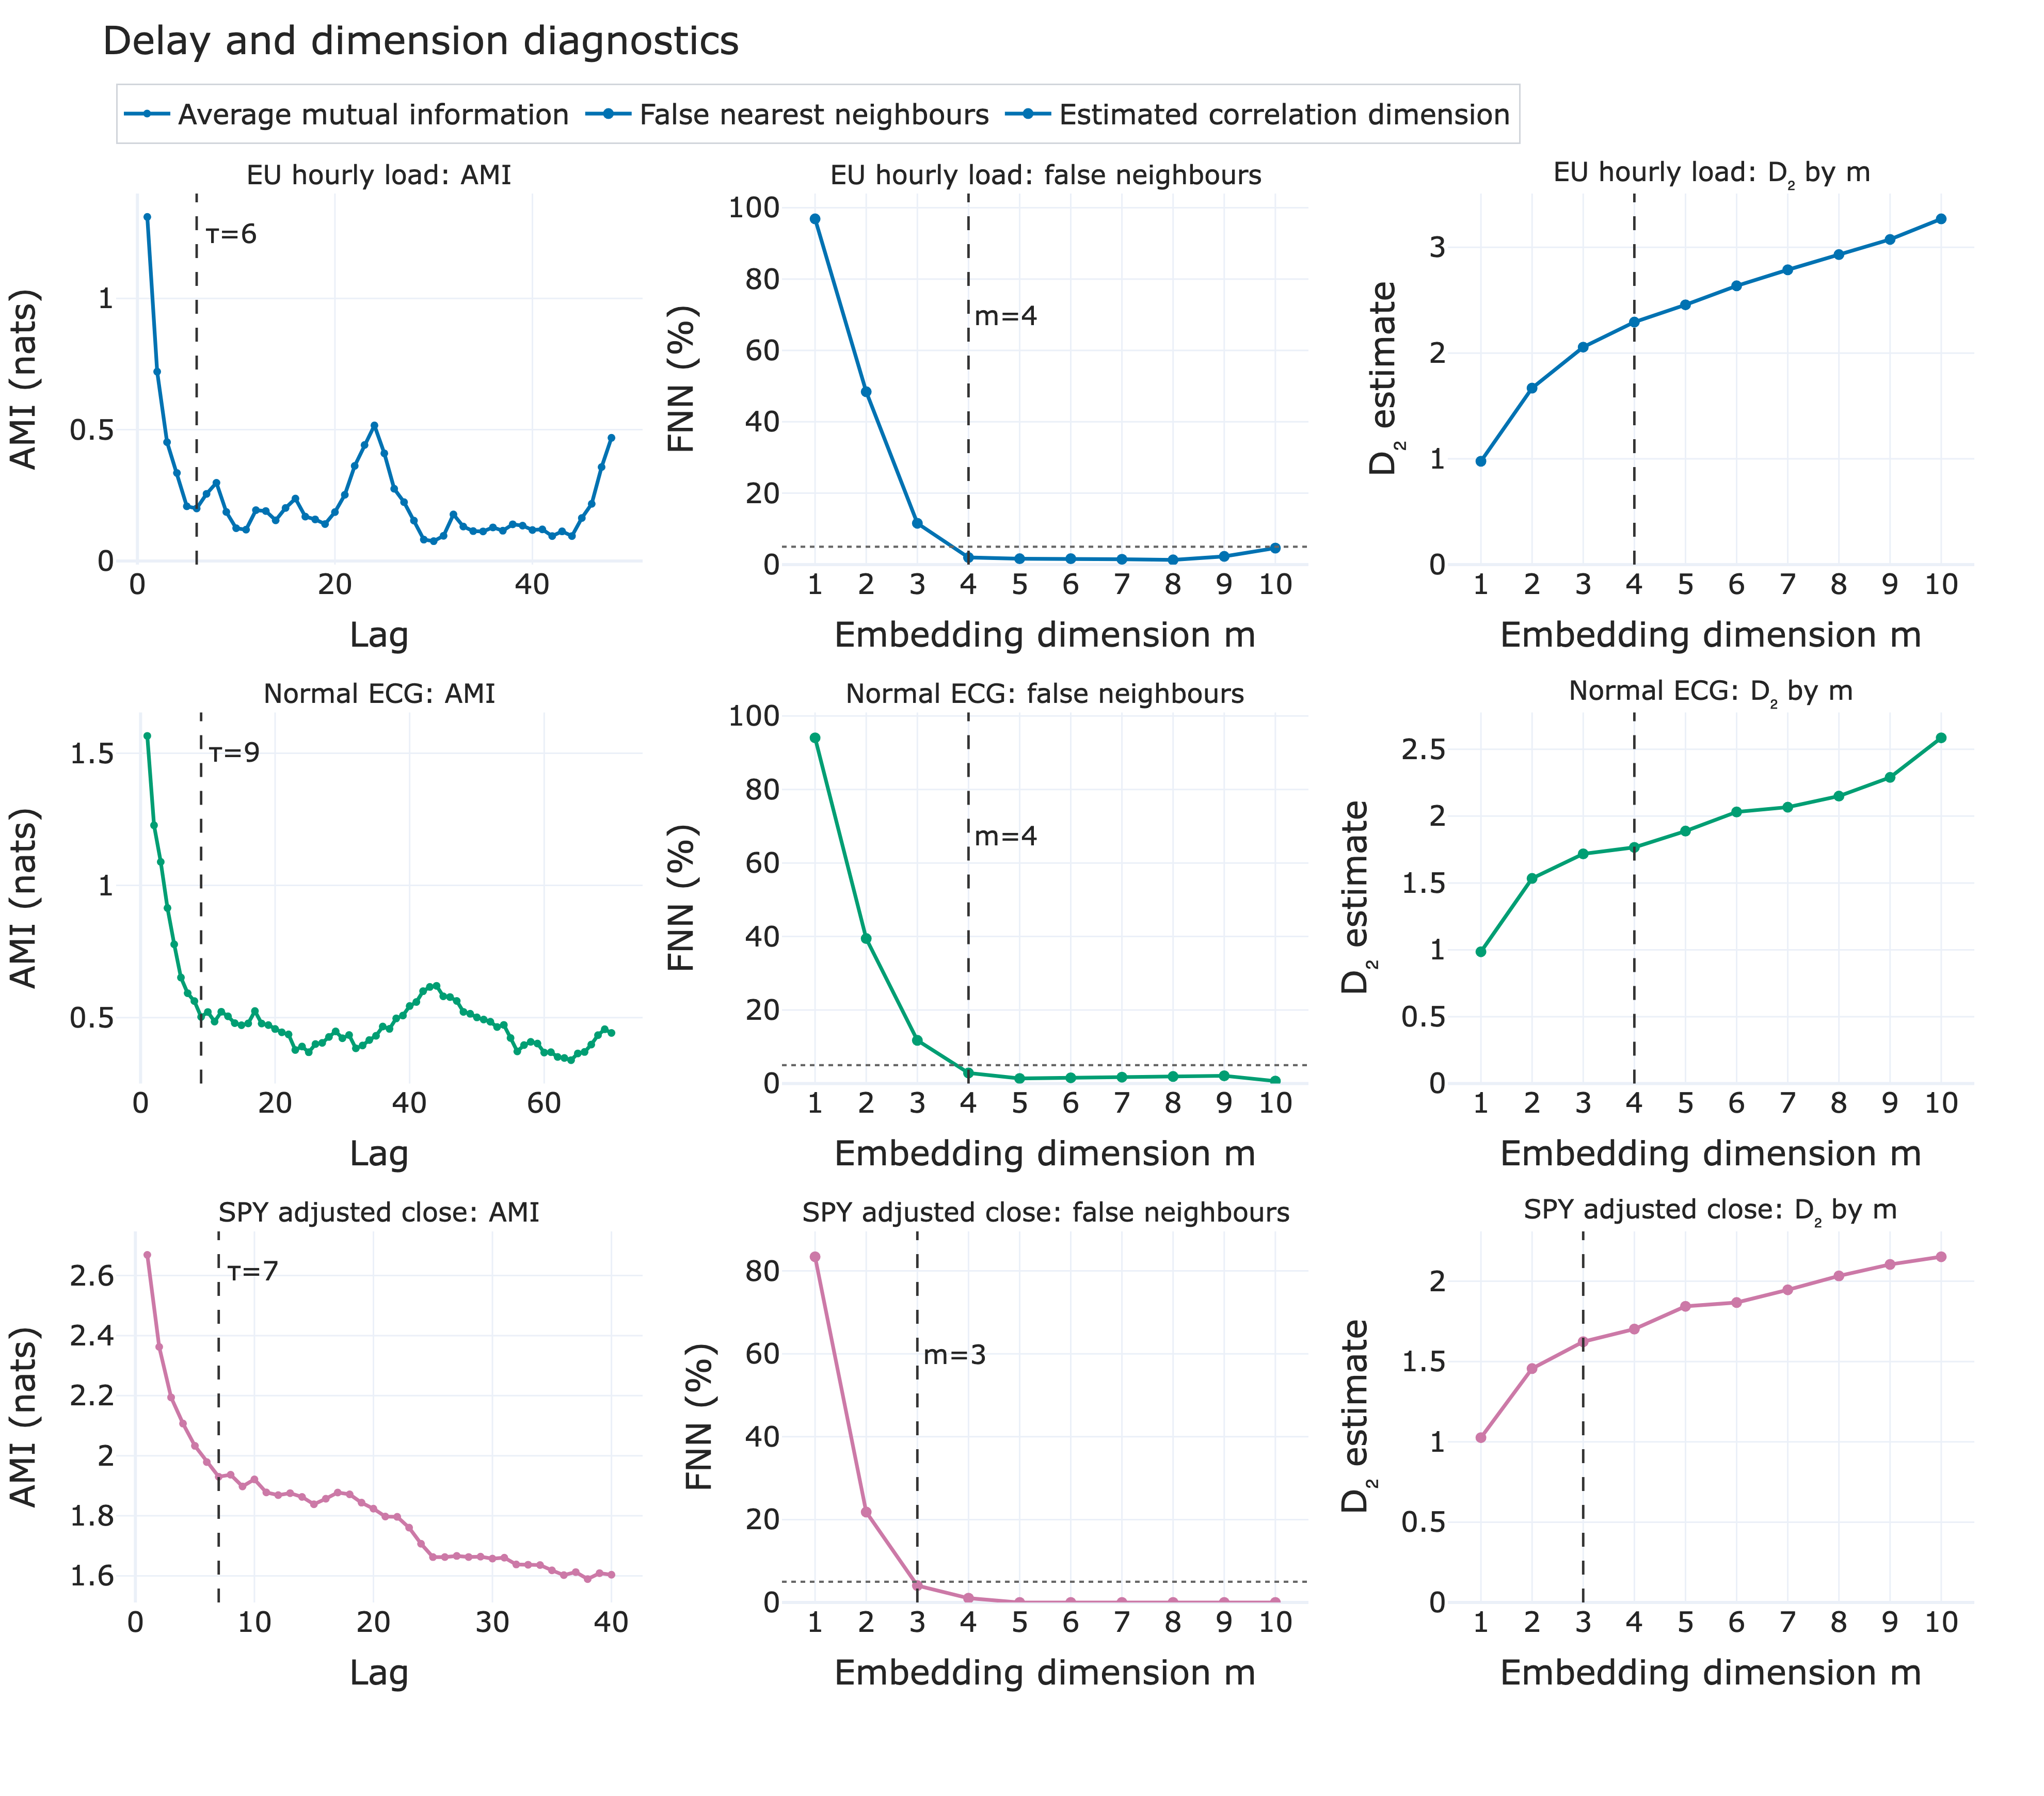

In [6]:
fig = make_subplots(
    rows=3, cols=3, horizontal_spacing=0.075, vertical_spacing=0.105,
    subplot_titles=tuple(
        title
        for item in series.values()
        for title in (f"{item.label}: AMI", f"{item.label}: false neighbours", f"{item.label}: D₂ by m")
    ),
)

for row, (key, item) in enumerate(series.items(), start=1):
    diagnostics = dimension_diagnostics[key]
    color = SERIES_COLORS[key]
    dimensions = np.arange(1, MAX_DIMENSION + 1)
    d2_values = [entry["dimension"] for entry in diagnostics["corr_by_m"]]

    fig.add_trace(
        go.Scatter(
            x=diagnostics["lags"],
            y=diagnostics["ami"],
            mode="lines+markers",
            name="Average mutual information",
            line=dict(color=color, width=2.4),
            marker=dict(size=5),
            showlegend=row == 1,
            legendgroup="ami",
        ),
        row=row,
        col=1,
    )
    fig.add_vline(x=diagnostics["delay"], line_color="#333333", line_dash="dash", line_width=1.6, row=row, col=1)
    fig.add_annotation(
        x=diagnostics["delay"], y=max(diagnostics["ami"]), text=f"τ={diagnostics['delay']}",
        showarrow=False, xshift=22, yshift=-10, row=row, col=1,
    )

    fig.add_trace(
        go.Scatter(
            x=dimensions,
            y=diagnostics["fnn"],
            mode="lines+markers",
            name="False nearest neighbours",
            line=dict(color=color, width=2.4),
            marker=dict(size=7),
            showlegend=row == 1,
            legendgroup="fnn",
        ),
        row=row,
        col=2,
    )
    fig.add_hline(y=5, line_color="#666666", line_dash="dot", line_width=1.4, row=row, col=2)
    fig.add_vline(x=diagnostics["dimension"], line_color="#333333", line_dash="dash", line_width=1.6, row=row, col=2)
    fig.add_annotation(
        x=diagnostics["dimension"], y=max(8, diagnostics["fnn"].max() * 0.72),
        text=f"m={diagnostics['dimension']}", showarrow=False, xshift=24, row=row, col=2,
    )

    fig.add_trace(
        go.Scatter(
            x=dimensions,
            y=d2_values,
            mode="lines+markers",
            name="Estimated correlation dimension",
            line=dict(color=color, width=2.4),
            marker=dict(size=7),
            showlegend=row == 1,
            legendgroup="d2",
        ),
        row=row,
        col=3,
    )
    fig.add_vline(x=diagnostics["dimension"], line_color="#333333", line_dash="dash", line_width=1.6, row=row, col=3)

for row in range(1, 4):
    fig.update_xaxes(title_text="Lag", row=row, col=1)
    fig.update_xaxes(title_text="Embedding dimension m", dtick=1, row=row, col=2)
    fig.update_xaxes(title_text="Embedding dimension m", dtick=1, row=row, col=3)
    fig.update_yaxes(title_text="AMI (nats)", row=row, col=1)
    fig.update_yaxes(title_text="FNN (%)", rangemode="tozero", row=row, col=2)
    fig.update_yaxes(title_text="D₂ estimate", rangemode="tozero", row=row, col=3)

fig.update_layout(title="Delay and dimension diagnostics")
show_and_save(
    fig, "dimension_diagnostics",
    "Mutual information, false-neighbour rates, and dimension estimates",
    height=1160, bottom_margin=125, legend_y=1.035,
)



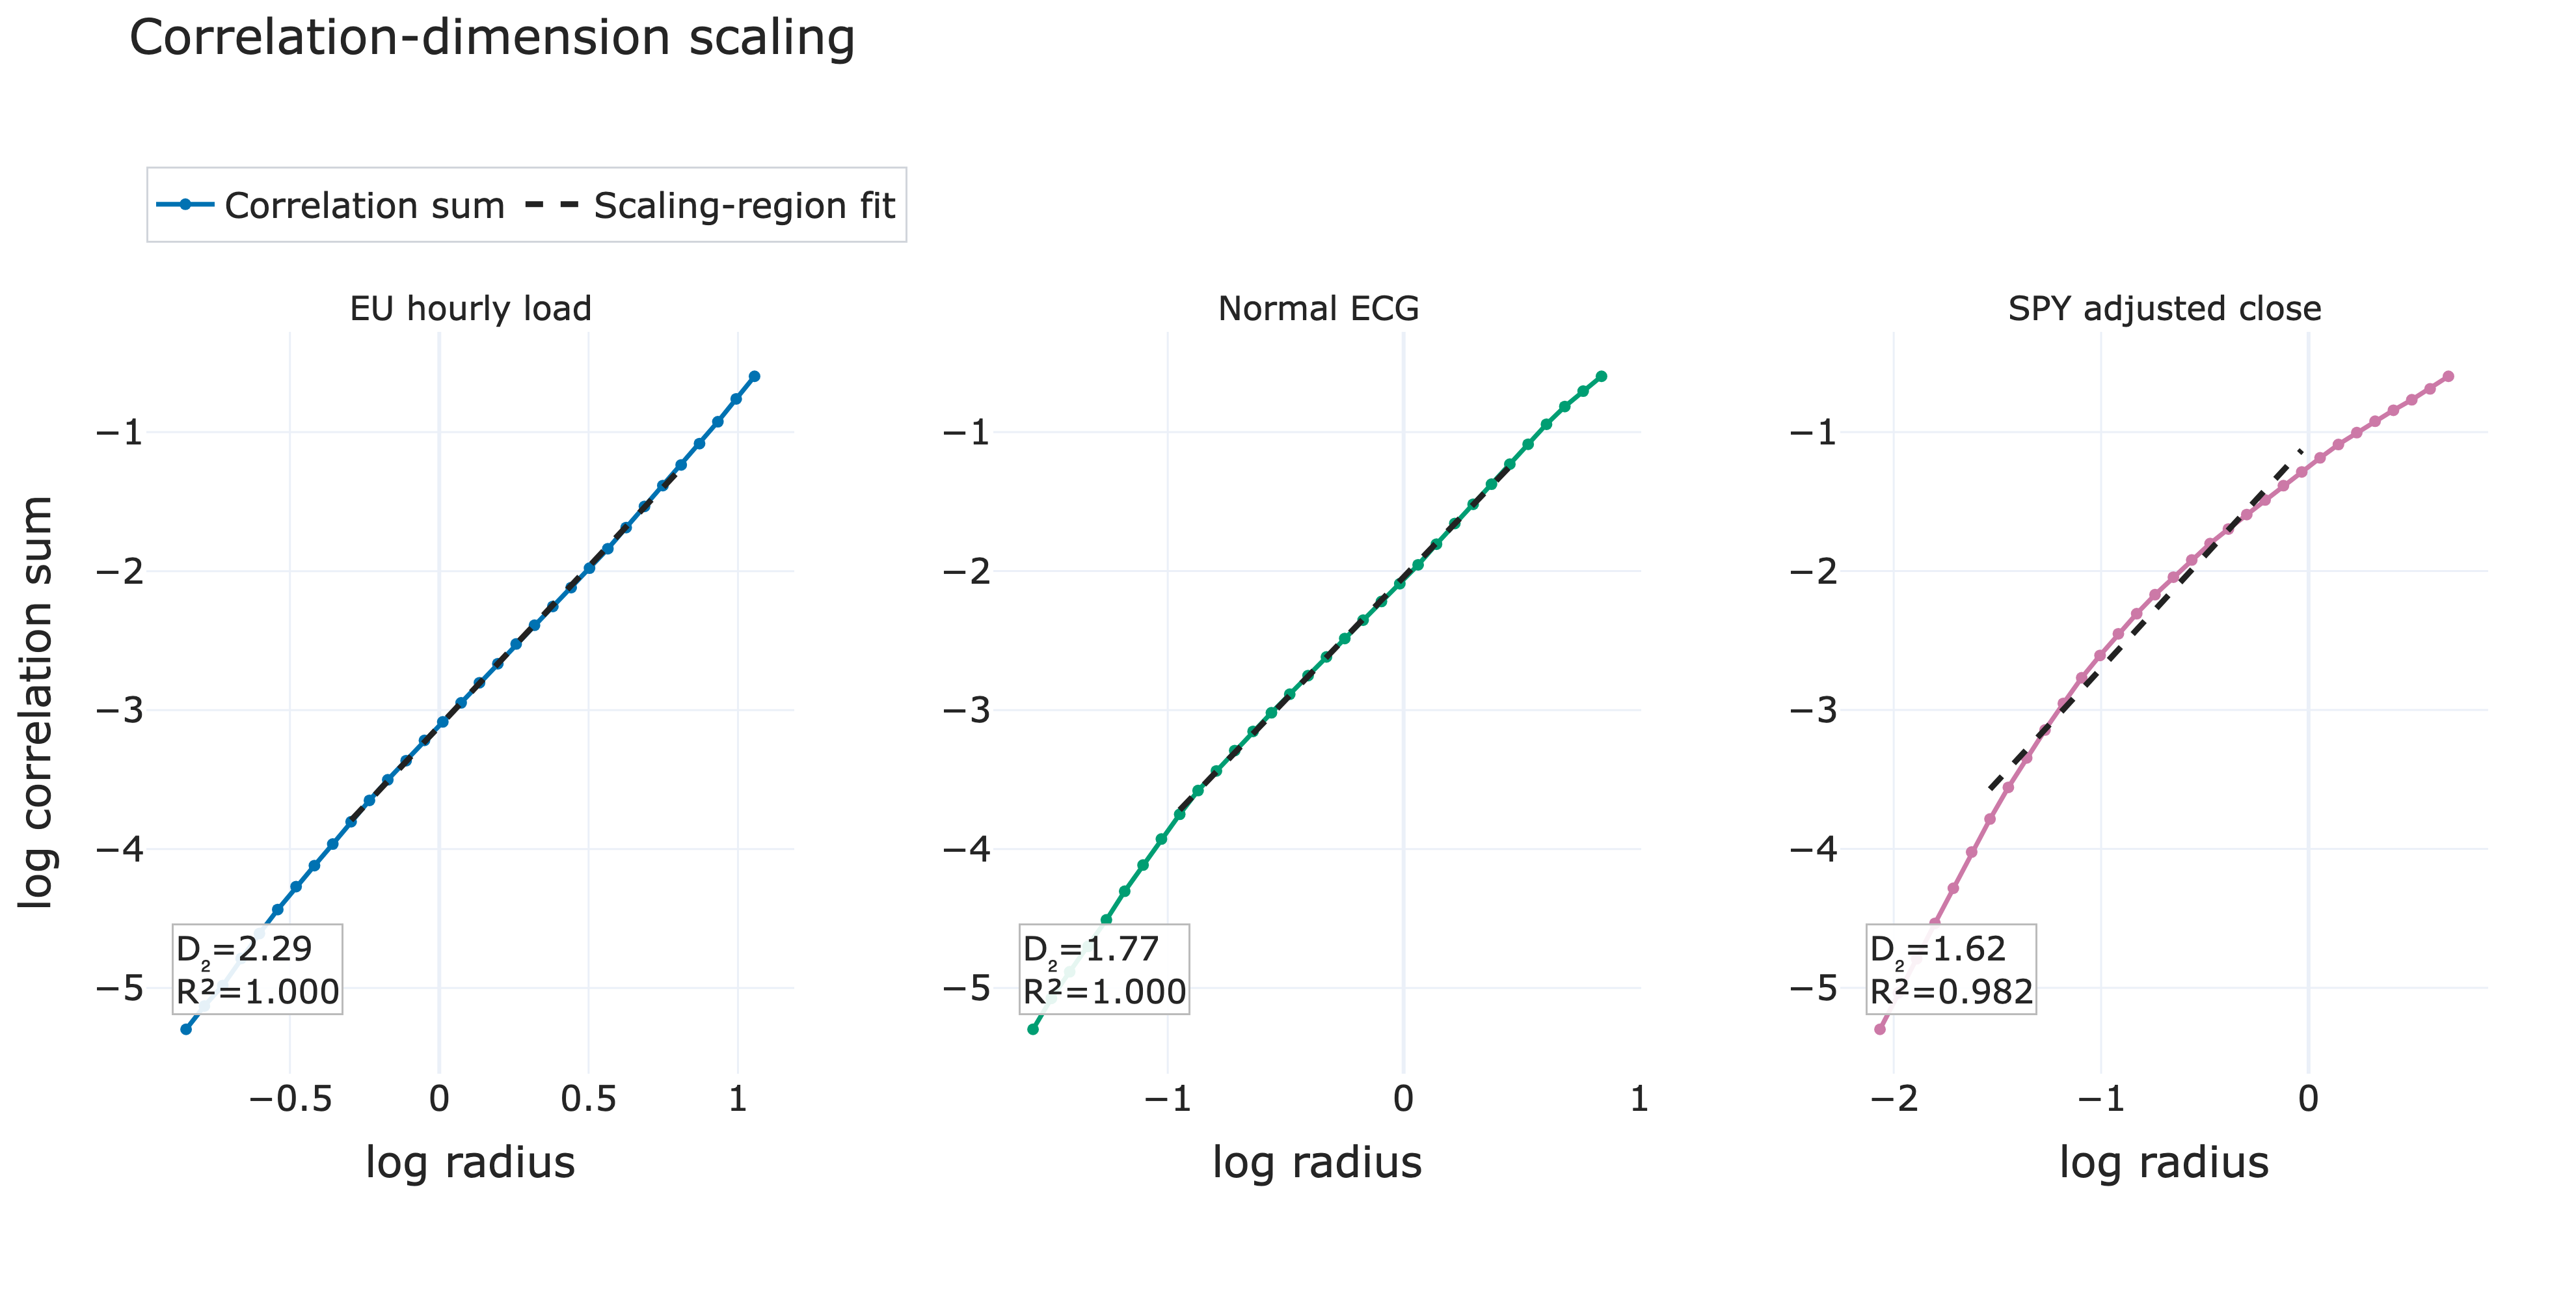

In [7]:
fig = make_subplots(
    rows=1, cols=3, horizontal_spacing=0.085,
    subplot_titles=tuple(item.label for item in series.values()),
)

for col, (key, item) in enumerate(series.items(), start=1):
    corr = dimension_diagnostics[key]["corr"]
    log_r = np.log(corr["radii"])
    log_c = np.log(np.maximum(corr["correlation_sum"], 1e-12))
    scaling = corr["scaling"]
    fit = corr["dimension"] * log_r[scaling] + corr["intercept"]
    fig.add_trace(
        go.Scatter(
            x=log_r,
            y=log_c,
            mode="lines+markers",
            name="Correlation sum",
            line=dict(color=SERIES_COLORS[key], width=2.4),
            marker=dict(size=6),
            showlegend=col == 1,
            legendgroup="sum",
        ),
        row=1,
        col=col,
    )
    fig.add_trace(
        go.Scatter(
            x=log_r[scaling],
            y=fit,
            mode="lines",
            name="Scaling-region fit",
            line=dict(color="#222222", width=3, dash="dash"),
            showlegend=col == 1,
            legendgroup="fit",
        ),
        row=1,
        col=col,
    )
    fig.add_annotation(
        x=0.04, y=0.08, xref=f"x{col} domain" if col > 1 else "x domain",
        yref=f"y{col} domain" if col > 1 else "y domain",
        text=f"D₂={corr['dimension']:.2f}<br>R²={corr['r2']:.3f}", showarrow=False,
        bgcolor="rgba(255,255,255,0.9)", bordercolor="#bbbbbb", borderwidth=1, align="left",
    )
    fig.update_xaxes(title_text="log radius", row=1, col=col)
    fig.update_yaxes(title_text="log correlation sum" if col == 1 else None, row=1, col=col)

fig.update_layout(title="Correlation-dimension scaling")
show_and_save(
    fig, "correlation_dimension_scaling",
    "Correlation-sum curves and scaling-region fits",
    height=670, top_margin=170, bottom_margin=120, legend_y=1.12,
)


### Findings from the dimension diagnostics

Dashed lines mark the selected delay and embedding dimension; dotted lines mark the 5% FNN criterion. In the scaling plots, pairs closer than one selected delay are excluded, and the dashed segment is fitted where $0.02 \leq C(r) \leq 0.30$.

All three development prefixes cross the 5% FNN threshold without reaching the ten-dimensional search cap. Electricity load selects $\tau=6$ and $m=4$ (1.98% false neighbours), while ECG selects $\tau=9$ and $m=4$ (2.86%). These compact reconstructions are consistent with their repeated daily and beat-scale geometry. SPY selects $\tau=7$ and $m=3$ (4.07%), but the result should be read as an efficient coordinate description of a persistent price path, not as evidence that the market is generated by a three-dimensional autonomous system.

At the selected embeddings, the estimated correlation dimensions are 2.29 for load, 1.77 for ECG and 1.62 for SPY. The scaling fits are nearly linear for load and ECG ($R^2>0.999$) and still strong for SPY ($R^2=0.982$). A key qualification is that $D_2$ continues to rise as more coordinates are introduced rather than settling on a clear plateau. The reported slopes therefore summarize a finite intermediate scale; this sample does not establish a saturated attractor dimension.


## 3. Local geometry in two dimensions

t-SNE is used only as a neighbourhood-preserving view of standardized delay vectors. Its axes have no physical units, and distances between remote groups are not reliable. The original phase space—not the t-SNE plane—is used for clustering and forecasting.


In [8]:
embeddings = {}
for key, item in series.items():
    diagnostics = dimension_diagnostics[key]
    phase, times = delay_embedding(standardize(item.values), diagnostics["dimension"], diagnostics["delay"])
    phase_scaled = StandardScaler().fit_transform(phase)
    perplexity = min(30, max(5, (len(phase_scaled) - 1) // 5))
    projection = TSNE(
        n_components=2, perplexity=perplexity, learning_rate="auto", init="pca",
        max_iter=1200, random_state=SEED,
    ).fit_transform(phase_scaled)
    local_quality = trustworthiness(phase_scaled, projection, n_neighbors=min(12, len(phase_scaled) // 5))
    embeddings[key] = {
        "phase": phase, "phase_scaled": phase_scaled, "times": times,
        "projection": projection, "trustworthiness": local_quality,
    }

quality_table = pd.DataFrame([
    {
        "Series": series[key].label,
        "Phase vectors": len(result["phase"]),
        "Original dimensions": result["phase"].shape[1],
        "t-SNE trustworthiness": result["trustworthiness"],
    }
    for key, result in embeddings.items()
])
show_table(quality_table, "Local-neighbourhood fidelity of the t-SNE views", precision=3, max_width=29)


+----------------------------------------------------------------------------------+
|                 Local-neighbourhood fidelity of the t-SNE views                  |
+--------------------+---------------+---------------------+-----------------------+
| Series             | Phase vectors | Original dimensions | t-SNE trustworthiness |
+--------------------+---------------+---------------------+-----------------------+
| EU hourly load     | 702           | 4                   | 0.996                 |
| Normal ECG         | 813           | 4                   | 0.995                 |
| SPY adjusted close | 736           | 3                   | 0.998                 |
+--------------------+---------------+---------------------+-----------------------+



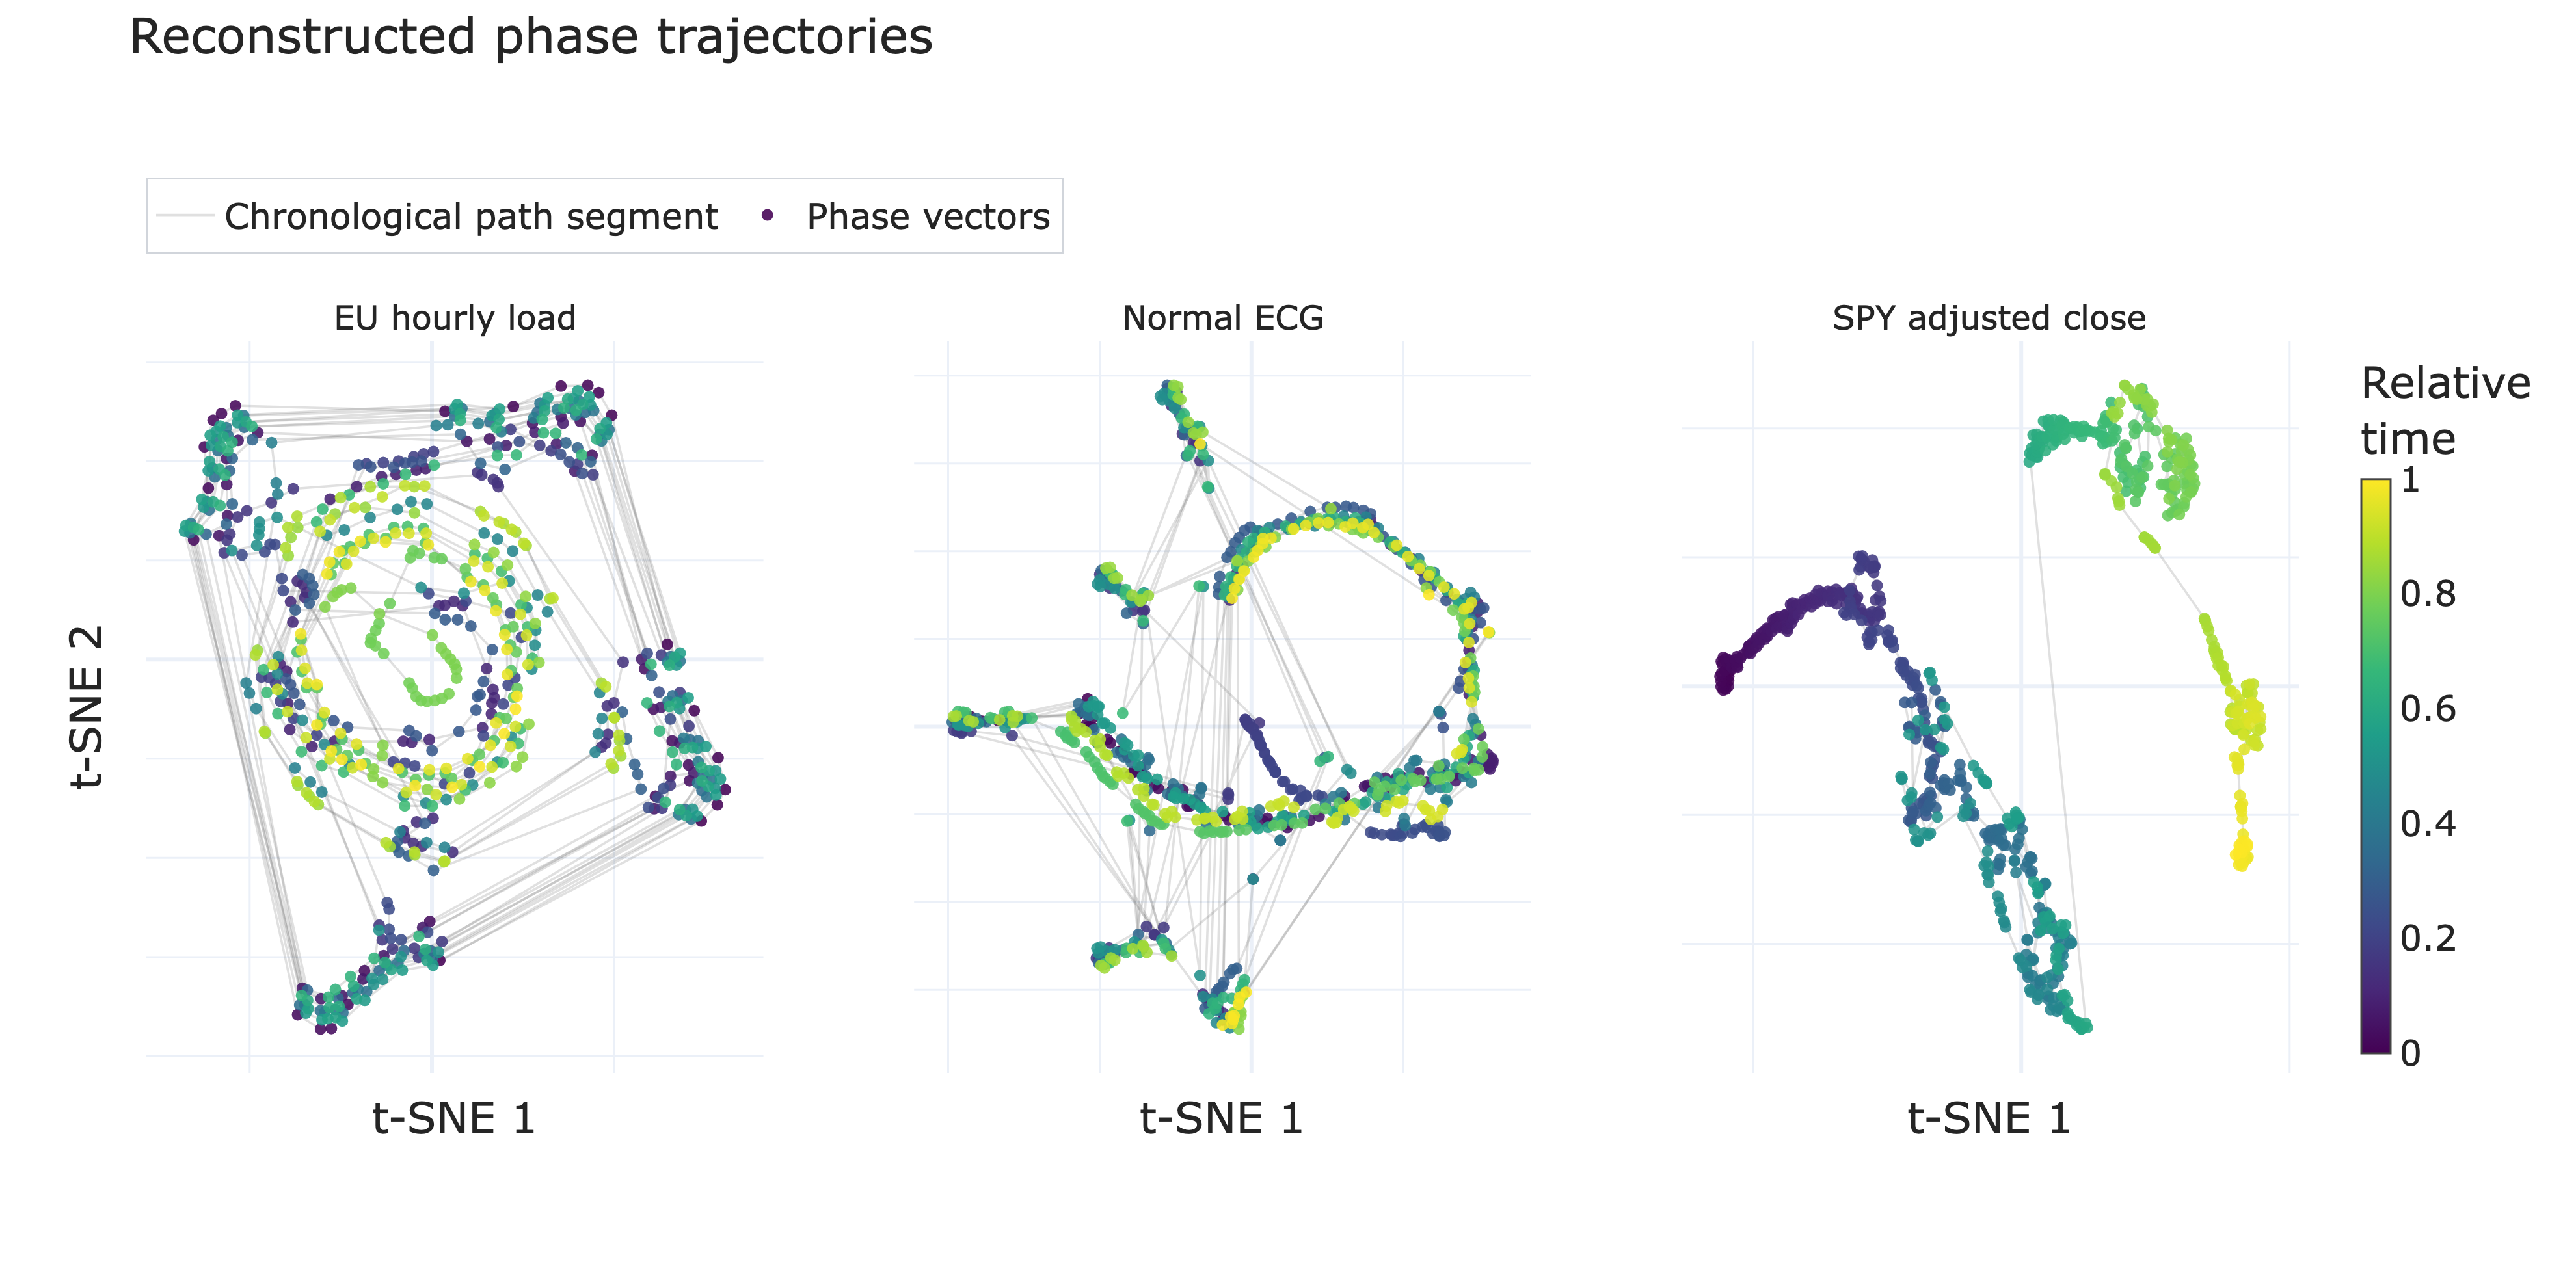

In [9]:
fig = make_subplots(
    rows=1, cols=3, horizontal_spacing=0.07,
    subplot_titles=tuple(item.label for item in series.values()),
)

for col, (key, item) in enumerate(series.items(), start=1):
    projection = embeddings[key]["projection"]
    times = embeddings[key]["times"]
    relative_time = np.linspace(0, 1, len(projection))
    segment_size = {"EU_Hourly_Load": 24, "ECG_TF_Normal": 140, "SPY_AdjClose": 50}[key]
    segment_ids = times // segment_size
    for segment_index, segment in enumerate(np.unique(segment_ids)):
        mask = segment_ids == segment
        fig.add_trace(
            go.Scatter(
                x=projection[mask, 0],
                y=projection[mask, 1],
                mode="lines",
                name="Chronological path segment",
                line=dict(color="rgba(90,90,90,0.19)", width=1.2),
                showlegend=col == 1 and segment_index == 0,
                legendgroup="path",
                hoverinfo="skip",
            ),
            row=1,
            col=col,
        )
    marker = dict(size=6, color=relative_time, colorscale="Viridis", opacity=0.88, showscale=col == 3)
    if col == 3:
        marker["colorbar"] = dict(title="Relative<br>time", x=1.02, thickness=15)
    fig.add_trace(
        go.Scatter(
            x=projection[:, 0],
            y=projection[:, 1],
            mode="markers",
            name="Phase vectors",
            marker=marker,
            showlegend=col == 1,
            legendgroup="points",
            customdata=np.column_stack([embeddings[key]["times"], relative_time]),
            hovertemplate="sample=%{customdata[0]}<br>relative time=%{customdata[1]:.2f}<extra></extra>",
        ),
        row=1,
        col=col,
    )
    fig.update_xaxes(title_text="t-SNE 1", showticklabels=False, row=1, col=col)
    fig.update_yaxes(title_text="t-SNE 2" if col == 1 else None, showticklabels=False, row=1, col=col)

fig.update_layout(title="Reconstructed phase trajectories")
show_and_save(
    fig, "tsne_phase_trajectories",
    "Time-coloured t-SNE views of reconstructed trajectories",
    height=650, top_margin=175, bottom_margin=100, legend_y=1.12,
)


### Reading the phase portraits

Colour advances through time. Grey paths are split at day, beat, or 50-session boundaries to avoid artificial long joins.

Trustworthiness is 0.996 for load, 0.995 for ECG and 0.998 for SPY, so the two-dimensional views preserve the local neighbour relations used for visual interpretation. This does not make between-group distances meaningful, but it supports reading the nearby paths and clusters.

The load portrait repeatedly revisits the same curved regions, with early and late colours interleaved. That recurrence is consistent with a daily cycle whose level and shape vary across the month. ECG traces a more compact recurring loop with small branches; the six colours repeatedly cover the main arc, while some branches coincide with between-beat joins or morphology differences. SPY is different: colour progresses along the portrait from early purple to late yellow with limited return to earlier regions. Its apparent geometry is primarily chronological drift through price levels rather than repeated motion around a stationary cycle.


## 4. Recurrent states and their transition graphs

Ward hierarchical clustering is applied to the standardized delay vectors. It minimizes the increase in within-cluster variance at each merge and therefore operates in the reconstructed state space where distances have a defined meaning. The number of states is selected from 3–8 by the silhouette score. Labels are then ordered by the mean current coordinate, so state 1 is the lowest-level regime and the largest label is the highest; this relabelling changes no cluster membership.

Every adjacent pair of state labels defines one directed transition, with edge weights given by row-normalized transition probabilities. Self-transitions are summarized inside each node so that rarer changes between states remain visible; they are still included in the transition probabilities and summary metrics.


In [10]:
def ordered_ward_states(phase: np.ndarray, phase_scaled: np.ndarray) -> tuple[np.ndarray, int, float, np.ndarray]:
    tree = linkage(phase_scaled, method="ward")
    scores = {}
    candidate_labels = {}
    for count in range(3, 9):
        labels = fcluster(tree, count, criterion="maxclust") - 1
        scores[count] = silhouette_score(phase_scaled, labels)
        candidate_labels[count] = labels
    best_count = max(scores, key=scores.get)
    labels = candidate_labels[best_count]
    order = sorted(range(best_count), key=lambda label: phase[labels == label, 0].mean())
    remap = {old: new for new, old in enumerate(order)}
    ordered = np.array([remap[label] for label in labels], dtype=int)
    return ordered, best_count, scores[best_count], tree


def transition_analysis(labels: np.ndarray, count: int) -> tuple[np.ndarray, np.ndarray, ig.Graph, dict]:
    counts = np.zeros((count, count), dtype=int)
    for source, target in zip(labels[:-1], labels[1:]):
        counts[source, target] += 1
    row_totals = counts.sum(axis=1, keepdims=True)
    probabilities = np.divide(counts, row_totals, out=np.zeros_like(counts, dtype=float), where=row_totals > 0)
    occupancy = np.bincount(labels, minlength=count) / len(labels)

    graph = ig.Graph(directed=True)
    graph.add_vertices(count)
    edges = [(source, target) for source in range(count) for target in range(count) if counts[source, target] > 0]
    graph.add_edges(edges)
    graph.es["count"] = [int(counts[source, target]) for source, target in edges]
    graph.es["probability"] = [float(probabilities[source, target]) for source, target in edges]
    graph.vs["occupancy"] = occupancy.tolist()

    stationary_entropy = 0.0
    for state in range(count):
        outgoing = probabilities[state]
        positive = outgoing[outgoing > 0]
        stationary_entropy += occupancy[state] * float(-np.sum(positive * np.log(positive)))
    normalized_entropy = stationary_entropy / np.log(count)
    persistence = float(np.sum(occupancy * np.diag(probabilities)))
    metrics = {
        "edges": graph.ecount(),
        "density": graph.density(loops=True),
        "persistence": persistence,
        "entropy": normalized_entropy,
    }
    return counts, probabilities, graph, metrics


cluster_rows = []
state_rows = []
transition_rows = []

for key, item in series.items():
    result = embeddings[key]
    labels, count, silhouette, tree = ordered_ward_states(result["phase"], result["phase_scaled"])
    counts, probabilities, graph, graph_metrics = transition_analysis(labels, count)
    result.update({
        "labels": labels, "state_count": count, "silhouette": silhouette, "linkage": tree,
        "transition_counts": counts, "transition_probabilities": probabilities,
        "graph": graph, "graph_metrics": graph_metrics,
    })
    cluster_rows.append({
        "Series": item.label,
        "States": count,
        "Silhouette": silhouette,
        "Directed edges": graph_metrics["edges"],
        "Density": graph_metrics["density"],
        "Persistence": graph_metrics["persistence"],
        "Entropy rate": graph_metrics["entropy"],
    })
    for state in range(count):
        mask = labels == state
        state_rows.append({
            "series": key,
            "state": state + 1,
            "occupancy": mask.mean(),
            "mean_level_z": result["phase_scaled"][mask, 0].mean(),
            "stay_probability": probabilities[state, state],
        })
        for target in range(count):
            transition_rows.append({
                "series": key,
                "source_state": state + 1,
                "target_state": target + 1,
                "count": counts[state, target],
                "probability": probabilities[state, target],
            })

cluster_summary = pd.DataFrame(cluster_rows)
state_summary = pd.DataFrame(state_rows)
transition_matrix = pd.DataFrame(transition_rows)
cluster_summary.to_csv(LAB_DIR / "cluster_graph_summary.csv", index=False)
state_summary.to_csv(LAB_DIR / "state_summary.csv", index=False)
transition_matrix.to_csv(LAB_DIR / "transition_probabilities.csv", index=False)
show_table(cluster_summary, "State-space clustering and transition structure", precision=3, max_width=23)


+--------------------------------------------------------------------------------------------------+
|                         State-space clustering and transition structure                          |
+--------------------+--------+------------+----------------+---------+-------------+--------------+
| Series             | States | Silhouette | Directed edges | Density | Persistence | Entropy rate |
+--------------------+--------+------------+----------------+---------+-------------+--------------+
| EU hourly load     | 7      | 0.279      | 24             | 0.490   | 0.825       | 0.297        |
| Normal ECG         | 8      | 0.385      | 27             | 0.422   | 0.874       | 0.222        |
| SPY adjusted close | 4      | 0.582      | 7              | 0.438   | 0.996       | 0.019        |
+--------------------+--------+------------+----------------+---------+-------------+--------------+



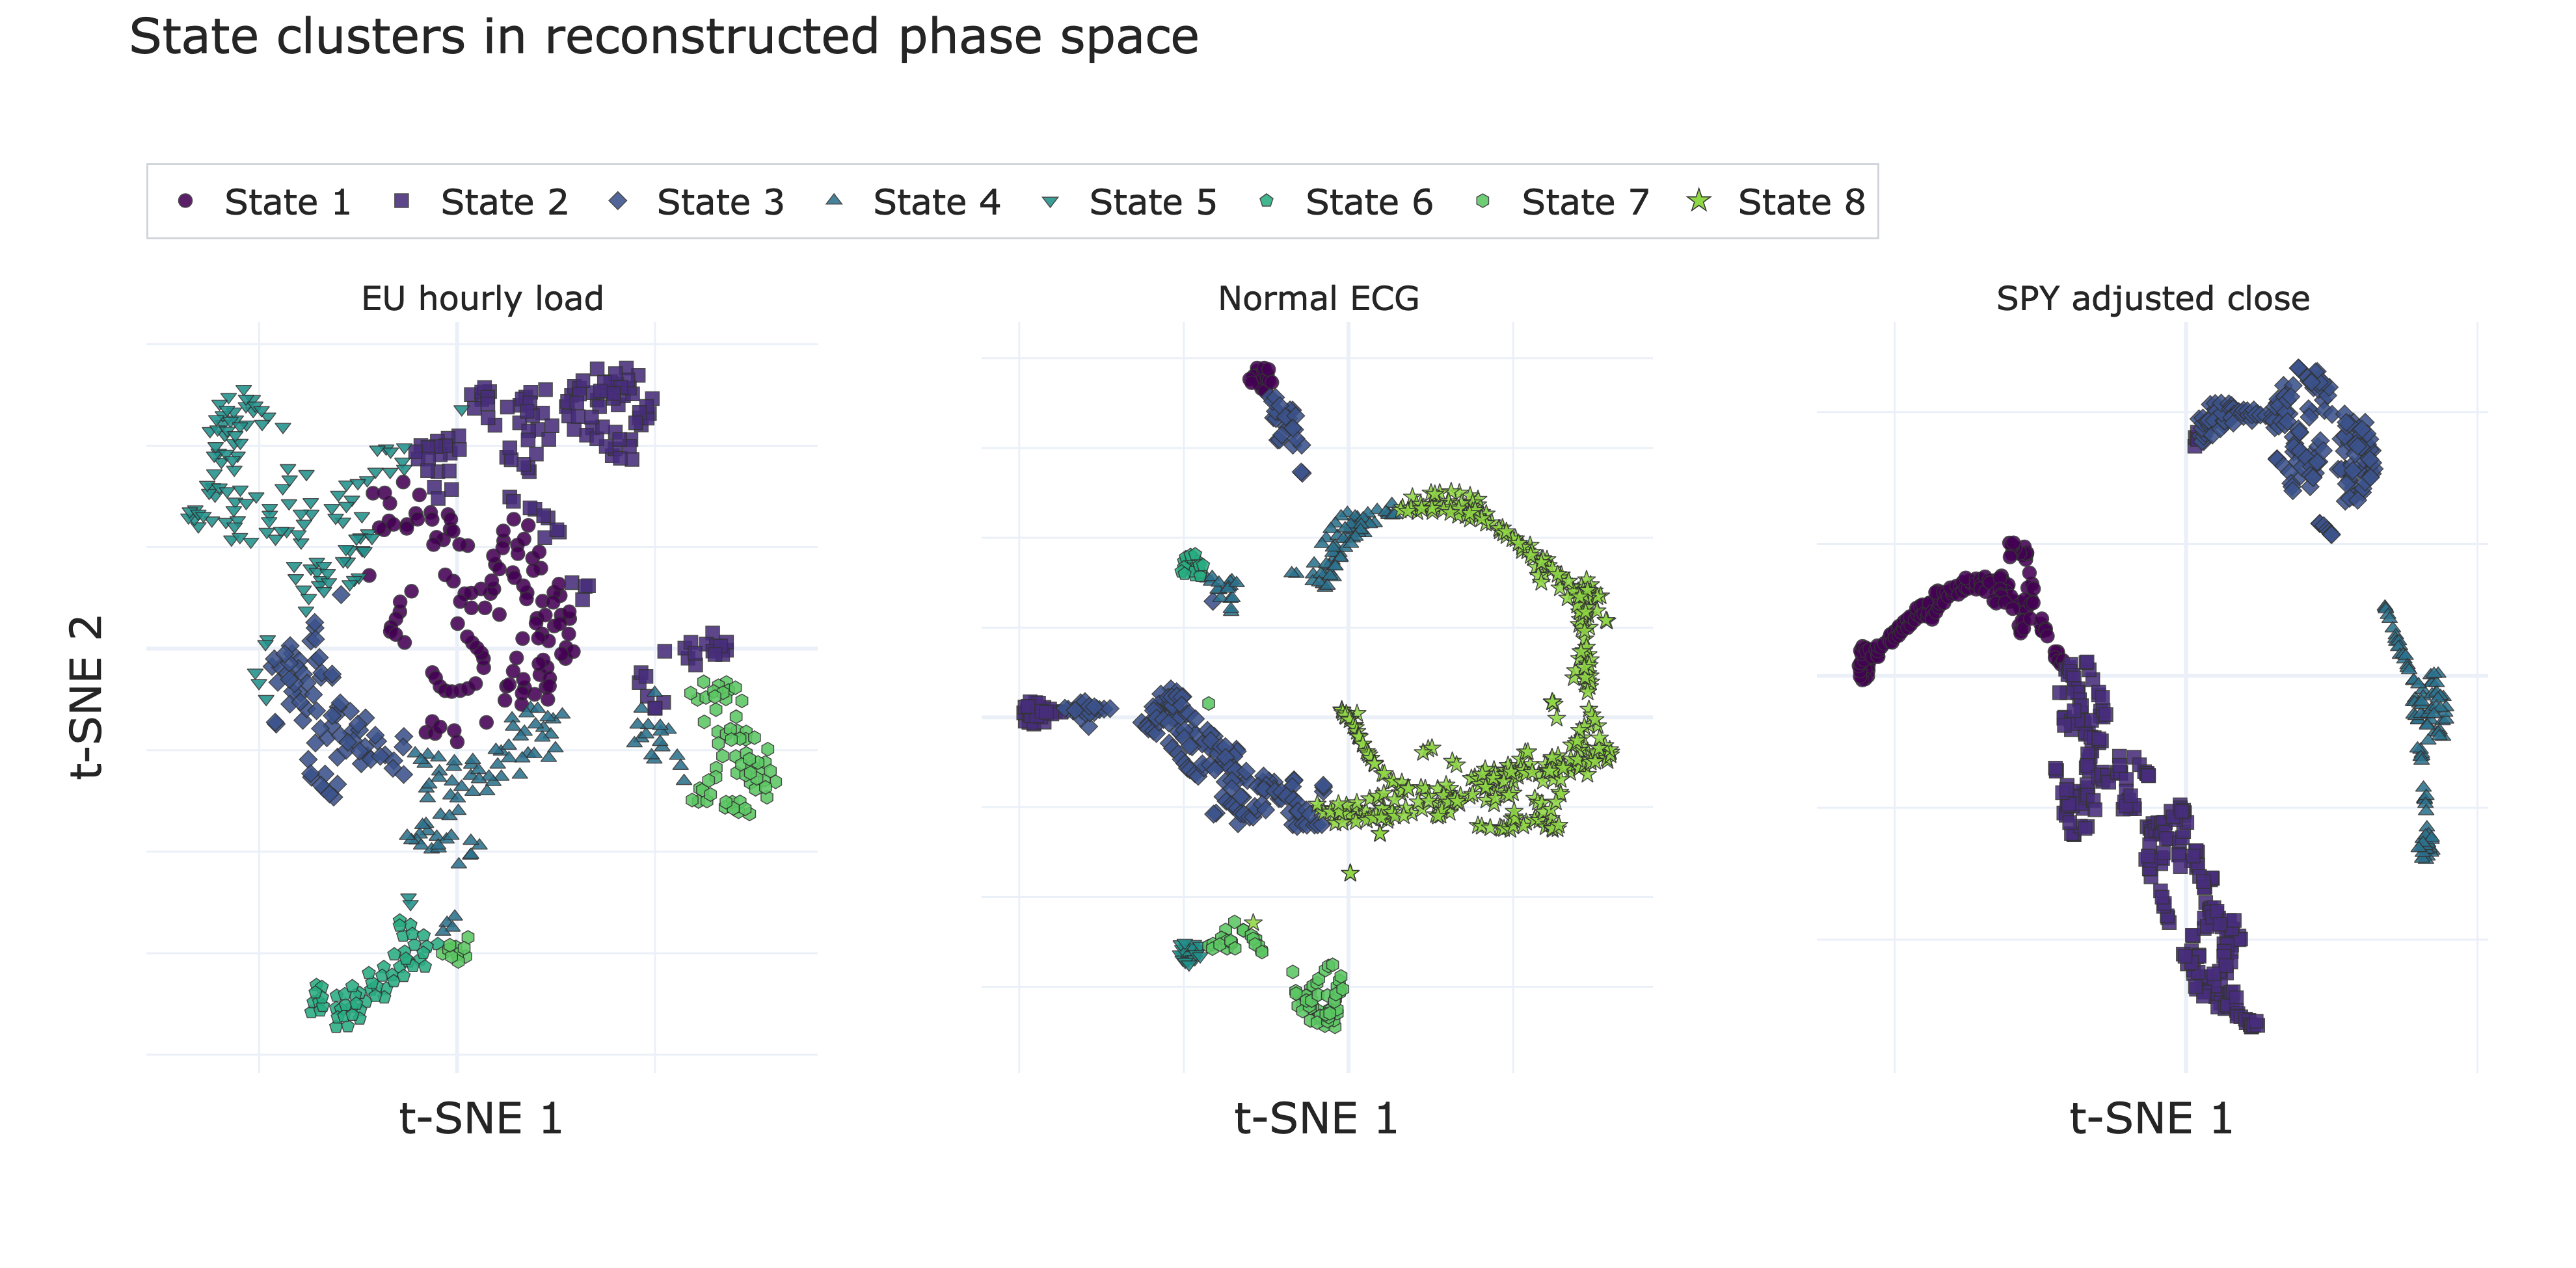

In [11]:
fig = make_subplots(
    rows=1, cols=3, horizontal_spacing=0.07,
    subplot_titles=tuple(item.label for item in series.values()),
)
max_states = max(result["state_count"] for result in embeddings.values())

for col, (key, item) in enumerate(series.items(), start=1):
    projection = embeddings[key]["projection"]
    labels = embeddings[key]["labels"]
    for state in range(embeddings[key]["state_count"]):
        mask = labels == state
        fig.add_trace(
            go.Scatter(
                x=projection[mask, 0],
                y=projection[mask, 1],
                mode="markers",
                name=f"State {state + 1}",
                marker=dict(
                    size=7,
                    color=STATE_COLORS[state],
                    symbol=STATE_SYMBOLS[state],
                    opacity=0.88,
                    line=dict(color="#333333", width=0.5),
                ),
                showlegend=col == 1,
                legendgroup=f"state-{state}",
                hovertemplate=f"State {state + 1}<extra></extra>",
            ),
            row=1,
            col=col,
        )
    fig.update_xaxes(title_text="t-SNE 1", showticklabels=False, row=1, col=col)
    fig.update_yaxes(title_text="t-SNE 2" if col == 1 else None, showticklabels=False, row=1, col=col)

for state in range(embeddings["EU_Hourly_Load"]["state_count"], max_states):
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            name=f"State {state + 1}",
            marker=dict(
                size=9,
                color=STATE_COLORS[state],
                symbol=STATE_SYMBOLS[state],
                line=dict(color="#333333", width=0.5),
            ),
            legendgroup=f"state-{state}",
        )
    )

fig.update_layout(title="State clusters in reconstructed phase space")
show_and_save(
    fig, "phase_state_clusters",
    "Ward states shown on reconstructed phase portraits",
    height=650, top_margin=165, bottom_margin=100, legend_y=1.11,
)



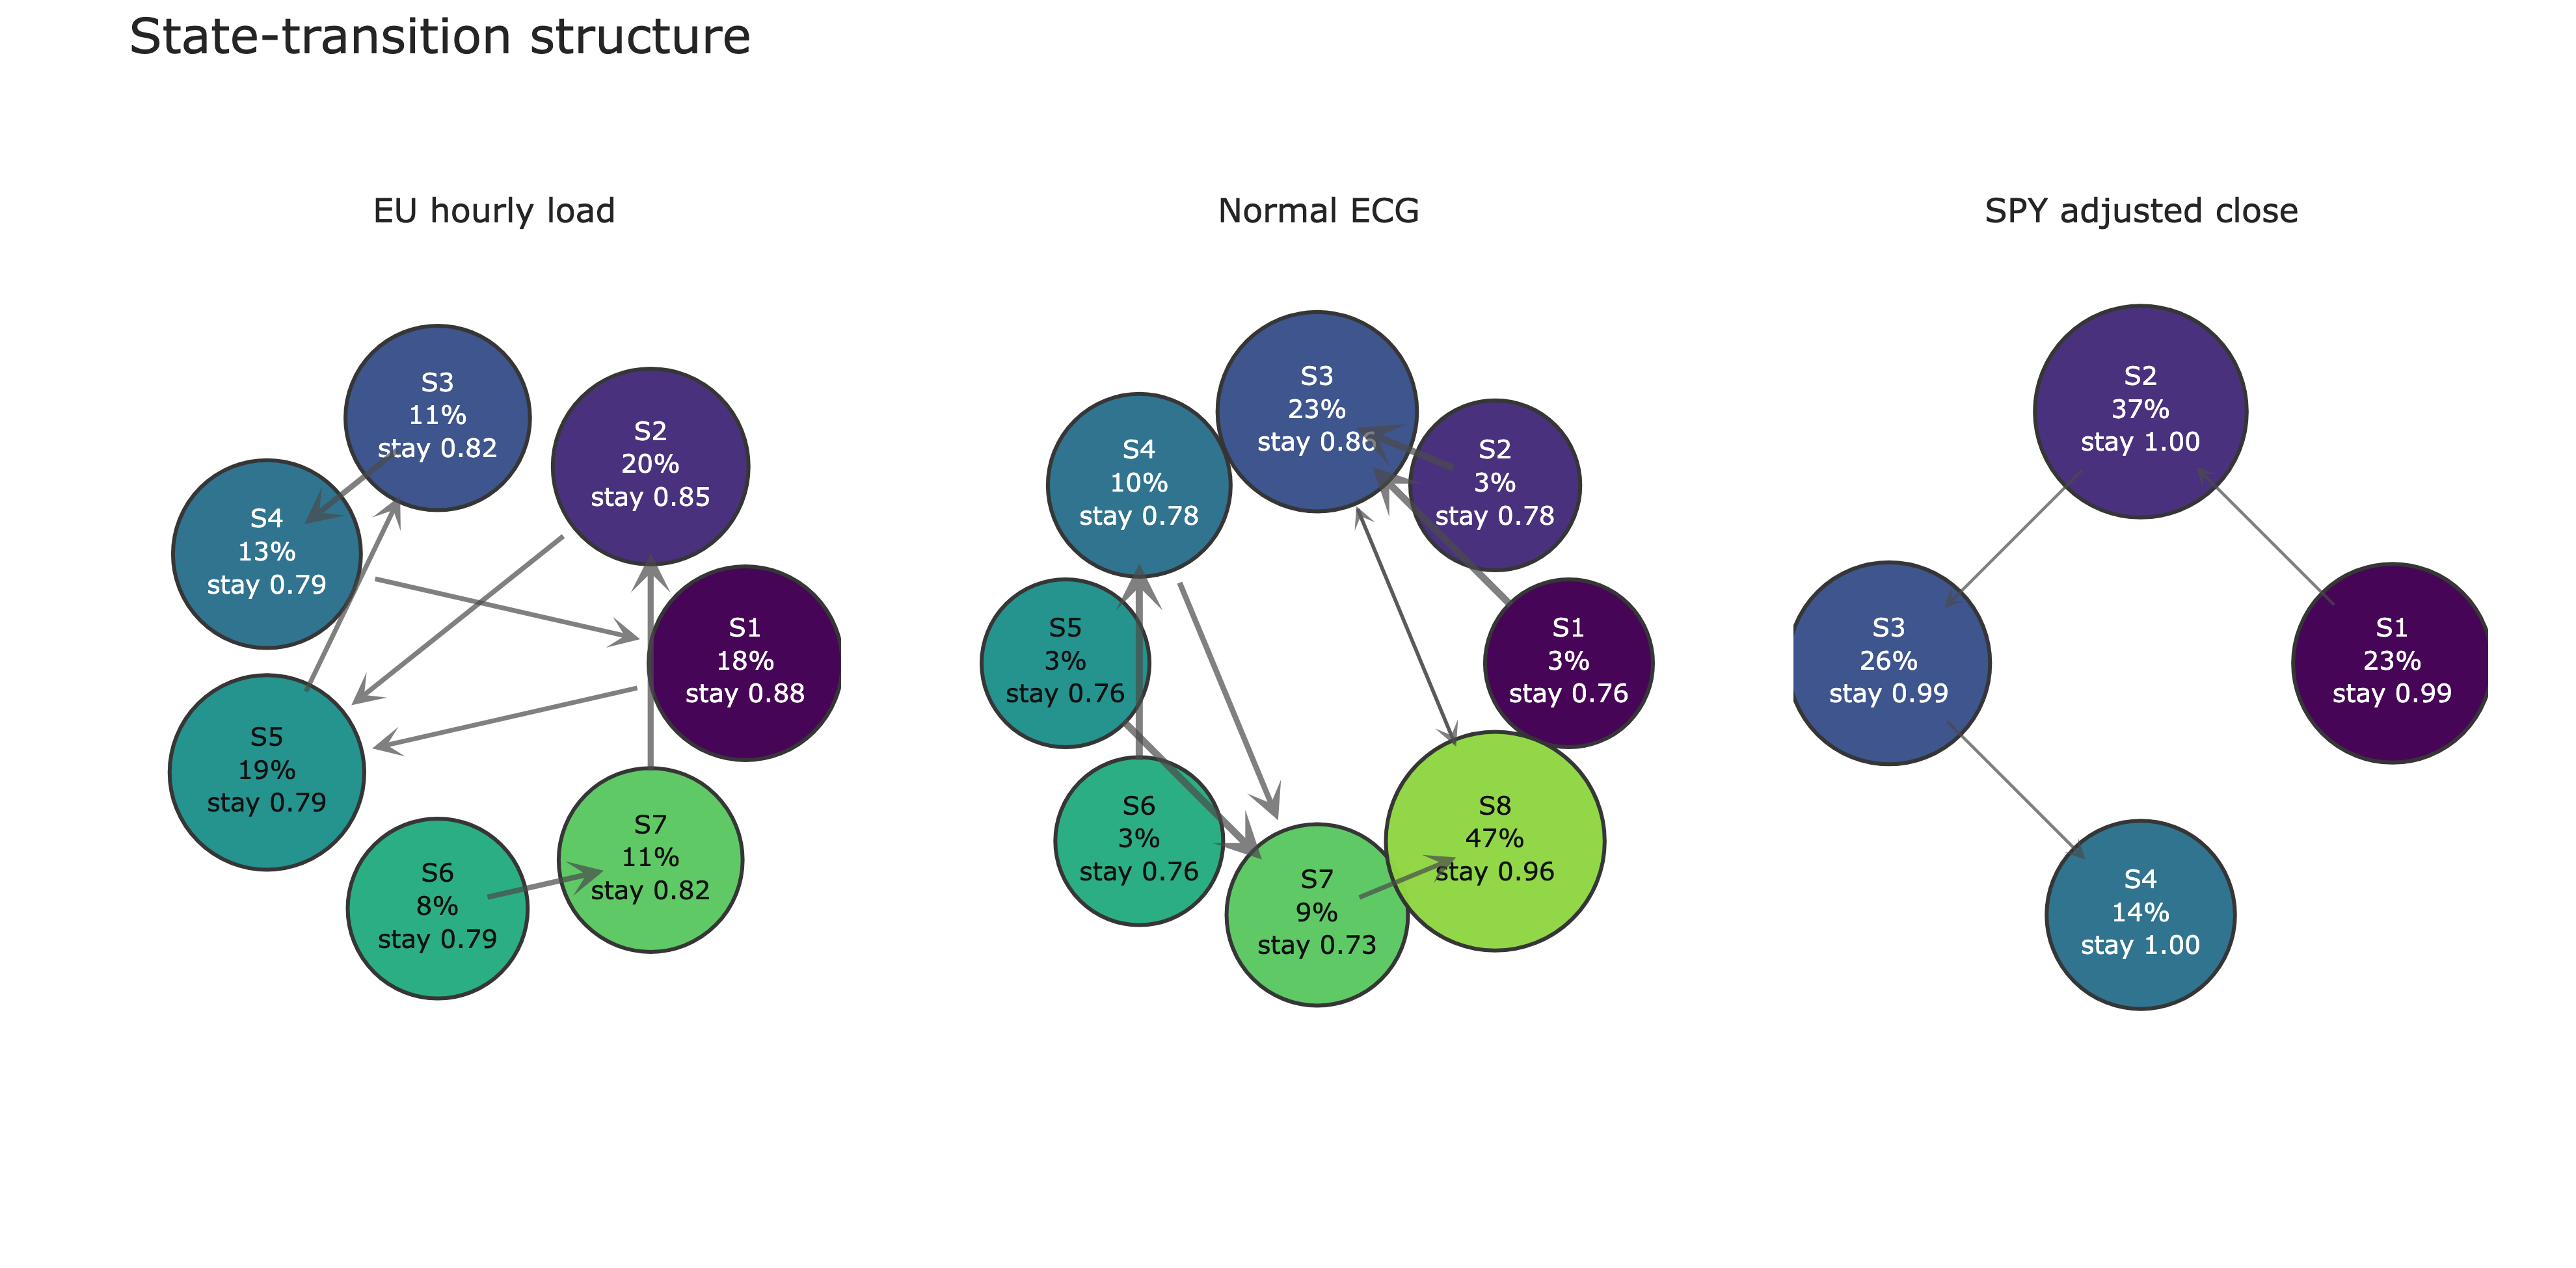

In [12]:
fig = make_subplots(
    rows=1, cols=3, horizontal_spacing=0.055,
    subplot_titles=tuple(item.label for item in series.values()),
)

for col, (key, item) in enumerate(series.items(), start=1):
    result = embeddings[key]
    graph = result["graph"]
    probabilities = result["transition_probabilities"]
    labels = result["labels"]
    count = result["state_count"]
    occupancy = np.bincount(labels, minlength=count) / len(labels)
    layout = graph.layout_circle()
    positions = np.asarray(layout.coords)
    axis_suffix = "" if col == 1 else str(col)
    xref, yref = f"x{axis_suffix}", f"y{axis_suffix}"

    off_diagonal = []
    for source in range(count):
        outgoing = [
            (target, probabilities[source, target])
            for target in range(count)
            if target != source and probabilities[source, target] > 0
        ]
        keep = sorted(outgoing, key=lambda pair: pair[1], reverse=True)[:1]
        off_diagonal.extend((source, target, probability) for target, probability in keep if probability > 0)

    for source, target, probability in off_diagonal:
        x0, y0 = positions[source]
        x1, y1 = positions[target]
        shorten = 0.22
        start_x, start_y = x0 + shorten * (x1 - x0), y0 + shorten * (y1 - y0)
        end_x, end_y = x1 - shorten * (x1 - x0), y1 - shorten * (y1 - y0)
        fig.add_annotation(
            x=end_x, y=end_y, ax=start_x, ay=start_y,
            xref=xref, yref=yref, axref=xref, ayref=yref,
            showarrow=True, arrowhead=3, arrowsize=1.1, arrowwidth=1.5 + 9 * probability,
            arrowcolor="rgba(75,75,75,0.70)", text="",
        )

    hovertext = [
        (
            f"State {state + 1}<br>"
            f"occupancy={occupancy[state]:.3f}<br>"
            f"stay probability={probabilities[state, state]:.3f}"
        )
        for state in range(count)
    ]
    fig.add_trace(
        go.Scatter(
            x=positions[:, 0],
            y=positions[:, 1],
            mode="markers+text",
            text=[
                f"S{state + 1}<br>{100 * occupancy[state]:.0f}%<br>stay {probabilities[state, state]:.2f}"
                for state in range(count)
            ],
            textposition="middle center",
            name="State",
            showlegend=False,
            marker=dict(
                size=78 + 50 * np.sqrt(occupancy),
                color=[STATE_COLORS[state] for state in range(count)],
                symbol="circle",
                line=dict(color="#333333", width=2),
                opacity=0.98,
            ),
            hovertext=hovertext,
            hovertemplate="%{hovertext}<extra></extra>",
            textfont=dict(
                size=13,
                color=[STATE_TEXT_COLORS[state] for state in range(count)],
            ),
        ),
        row=1,
        col=col,
    )
    fig.update_xaxes(range=[-1.38, 1.38], visible=False, row=1, col=col)
    fig.update_yaxes(
        range=[-1.38, 1.38], visible=False,
        scaleanchor=xref, scaleratio=1, row=1, col=col,
    )

fig.update_layout(title="State-transition structure")
show_and_save(
    fig, "state_transition_graphs_igraph",
    "State occupancy and strongest transition probabilities",
    height=650, top_margin=120, bottom_margin=90,
)


### Findings from the state models

State numbers run from lower to higher mean current value. Clustering uses the original phase vectors rather than the t-SNE coordinates. In the transition graphs, node text gives state, occupancy, and self-transition probability; arrow width shows the strongest outgoing change. All transitions remain included in the reported probabilities and metrics.

The selected partitions contain seven load states, eight ECG states and four SPY states. Separation is weakest for load (silhouette 0.279), where neighbouring parts of the daily cycle overlap, and moderate for ECG (0.385). SPY has the highest silhouette (0.582), but its time-ordered portrait shows why: the clusters mainly partition successive price levels rather than recurring dynamical regimes.

Load has the richest switching structure: 24 directed edges, persistence 0.825 and normalized entropy rate 0.297. The strongest changes trace a plausible cycle through low, rising, high and falling demand states rather than one dominant jump. ECG is more persistent (0.874) and concentrates 47% of its vectors in state 8, which has a 0.955 probability of remaining there; short, sharper waveform regions occupy the smaller states and produce the directed excursions around the graph. Some of those excursions occur near concatenated beat boundaries and should not be read as physiological state changes.

SPY is almost absorbing at this sampling scale: weighted persistence is 0.996 and entropy rate only 0.019. Its off-diagonal probabilities are at most 0.006, and every state stays in place more than 99% of the time. The clean clusters and sparse graph therefore describe slow level drift. They are visually strong but dynamically less recurrent than the load or ECG graphs.


## 5. Does the reconstructed input help the LSTM?

The Lab 4 LSTM receives every observation in a fixed recent window. Here it is replaced by the estimated state vector $[x_{t-(m-1)\tau},\ldots,x_t]$: the same one-layer LSTM with 16 hidden units, Adam, chronological validation, early stopping and recursive forecasting is retained. Both representations use the same initialization seed at each test block. This controls their starting weights, while the different inputs may lead to different optimization paths and stopping epochs. Each block has one seeded fit per representation, so variation across random initializations is not measured.

For each horizon, the final $10h$ observations form ten adjacent, non-overlapping test blocks. Every model is refitted using only the prefix available at its origin. The corresponding Lab 4 forecasts provide the paired baseline. MAPE is the required score, while MAE is retained because percentage error is unstable when the normalized ECG crosses zero.


In [13]:
class LSTMForecaster(nn.Module):
    def __init__(self, hidden_size: int = 16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        sequence, _ = self.lstm(x.unsqueeze(-1))
        return self.output(sequence[:, -1]).squeeze(-1)


def embedding_windows(values: np.ndarray, dimension: int, delay: int) -> tuple[np.ndarray, np.ndarray]:
    span = (dimension - 1) * delay
    end_times = np.arange(span, len(values) - 1)
    inputs = np.array([
        [values[end - lag * delay] for lag in range(dimension - 1, -1, -1)]
        for end in end_times
    ], dtype=np.float32)
    targets = np.asarray(values[end_times + 1], dtype=np.float32)
    return inputs, targets


def embedding_lstm_forecast(
    train: np.ndarray,
    horizon: int,
    dimension: int,
    delay: int,
    seed: int,
) -> tuple[np.ndarray, float, float, int]:
    fit_start = time.perf_counter()
    torch.manual_seed(seed)
    center = float(np.mean(train))
    scale = float(np.std(train))
    if scale < 1e-12:
        scale = 1.0
    normalized = (np.asarray(train, dtype=float) - center) / scale
    x, y = embedding_windows(normalized, dimension, delay)
    x, y = x[-MAX_TRAIN_WINDOWS:], y[-MAX_TRAIN_WINDOWS:]

    validation_size = max(1, int(np.ceil(len(x) * VALIDATION_SHARE)))
    x_train = torch.from_numpy(x[:-validation_size])
    y_train = torch.from_numpy(y[:-validation_size])
    x_valid = torch.from_numpy(x[-validation_size:])
    y_valid = torch.from_numpy(y[-validation_size:])

    model = LSTMForecaster(hidden_size=16)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    loss_function = nn.MSELoss()
    best_loss = np.inf
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    epochs_run = 0

    for epoch in range(MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        loss = loss_function(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            validation_loss = float(loss_function(model(x_valid), y_valid))
        epochs_run = epoch + 1
        if validation_loss < best_loss - 1e-6:
            best_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    model.load_state_dict(best_state)
    fit_seconds = time.perf_counter() - fit_start

    forecast_start = time.perf_counter()
    history = normalized.tolist()
    predictions = []
    model.eval()
    with torch.no_grad():
        for _ in range(horizon):
            state = [history[-1 - lag * delay] for lag in range(dimension - 1, -1, -1)]
            model_input = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            next_value = float(model(model_input).item())
            history.append(next_value)
            predictions.append(center + scale * next_value)
    forecast_seconds = time.perf_counter() - forecast_start
    return np.asarray(predictions), fit_seconds, forecast_seconds, epochs_run


def test_origins(length: int, horizon: int) -> list[int]:
    first = length - N_SPLITS * horizon
    return [first + split * horizon for split in range(N_SPLITS)]


def mape(actual: np.ndarray, predicted: np.ndarray) -> float:
    valid = np.abs(actual) > 1e-12
    return float(100 * np.mean(np.abs((actual[valid] - predicted[valid]) / actual[valid])))


lab4_dir = LAB_DIR.parent / "lab-4"
previous_results = pd.read_csv(lab4_dir / "forecast_results_raw.csv")
previous_results = previous_results[previous_results["model"] == "LSTM"].copy()
previous_results["model"] = "Lab 4 LSTM"
previous_paths = pd.read_csv(lab4_dir / "forecast_paths.csv")
previous_paths = previous_paths[previous_paths["model"] == "LSTM"].copy()
previous_paths["model"] = "Lab 4 LSTM"
baseline_seeds = previous_results.set_index(["series", "horizon", "split"])["seed"]
assert len(baseline_seeds) == len(series) * len(HORIZONS) * N_SPLITS
assert baseline_seeds.index.is_unique and baseline_seeds.notna().all()

forecast_rows = []
forecast_path_rows = []
for key, item in series.items():
    diagnostics = dimension_diagnostics[key]
    for horizon in HORIZONS:
        for split, origin in enumerate(test_origins(len(item.values), horizon), start=1):
            actual = item.values[origin:origin + horizon]
            seed = int(baseline_seeds.loc[(key, horizon, split)])
            predicted, fit_seconds, forecast_seconds, epochs = embedding_lstm_forecast(
                item.values[:origin], horizon, diagnostics["dimension"], diagnostics["delay"],
                seed=seed,
            )
            forecast_rows.append({
                "series": key, "series_label": item.label, "horizon": horizon, "split": split,
                "origin": origin, "model": "Embedding-aware LSTM", "mape": mape(actual, predicted),
                "seed": seed,
                "mae": float(np.mean(np.abs(actual - predicted))), "fit_seconds": fit_seconds,
                "forecast_seconds": forecast_seconds, "epochs": epochs,
            })
            for step, (observed, estimate) in enumerate(zip(actual, predicted), start=1):
                forecast_path_rows.append({
                    "series": key, "horizon": horizon, "split": split, "model": "Embedding-aware LSTM",
                    "step": step, "actual": observed, "predicted": estimate,
                })

new_results = pd.DataFrame(forecast_rows)
new_paths = pd.DataFrame(forecast_path_rows)
new_results.to_csv(LAB_DIR / "embedding_lstm_results_raw.csv", index=False)
new_paths.to_csv(LAB_DIR / "embedding_lstm_paths.csv", index=False)

comparison_results = pd.concat([
    previous_results[["series", "series_label", "horizon", "split", "origin", "model", "mape", "mae"]],
    new_results[["series", "series_label", "horizon", "split", "origin", "model", "mape", "mae"]],
], ignore_index=True)
comparison_results.to_csv(LAB_DIR / "lstm_comparison_raw.csv", index=False)

summary_rows = []
for key, item in series.items():
    for horizon in HORIZONS:
        old = comparison_results[
            (comparison_results["series"] == key) & (comparison_results["horizon"] == horizon) &
            (comparison_results["model"] == "Lab 4 LSTM")
        ]
        new = comparison_results[
            (comparison_results["series"] == key) & (comparison_results["horizon"] == horizon) &
            (comparison_results["model"] == "Embedding-aware LSTM")
        ]
        summary_rows.append({
            "Series": item.label,
            "Horizon": horizon,
            "Lab 4 mean MAPE": old["mape"].mean(),
            "Embedded mean MAPE": new["mape"].mean(),
            "Embedded median MAPE": new["mape"].median(),
            "MAPE change, %": 100 * (new["mape"].mean() / old["mape"].mean() - 1),
            "Embedded mean MAE": new["mae"].mean(),
        })

forecast_summary = pd.DataFrame(summary_rows)
forecast_summary.to_csv(LAB_DIR / "lstm_comparison_summary.csv", index=False)
for label in forecast_summary["Series"].unique():
    show_table(
        forecast_summary[forecast_summary["Series"] == label].drop(columns="Series"),
        f"Paired LSTM comparison — {label}", precision=3, max_width=23,
    )


+------------------------------------------------------------------------------------------------------------+
|                                  Paired LSTM comparison — EU hourly load                                   |
+---------+-----------------+--------------------+----------------------+----------------+-------------------+
| Horizon | Lab 4 mean MAPE | Embedded mean MAPE | Embedded median MAPE | MAPE change, % | Embedded mean MAE |
+---------+-----------------+--------------------+----------------------+----------------+-------------------+
| 1       | 4.811           | 4.795              | 3.597                | -0.343         | 1313.775          |
| 7       | 9.260           | 9.847              | 6.034                | 6.338          | 2407.183          |
| 14      | 13.141          | 10.317             | 9.284                | -21.491        | 2755.034          |
+---------+-----------------+--------------------+----------------------+----------------+-------------------+
+


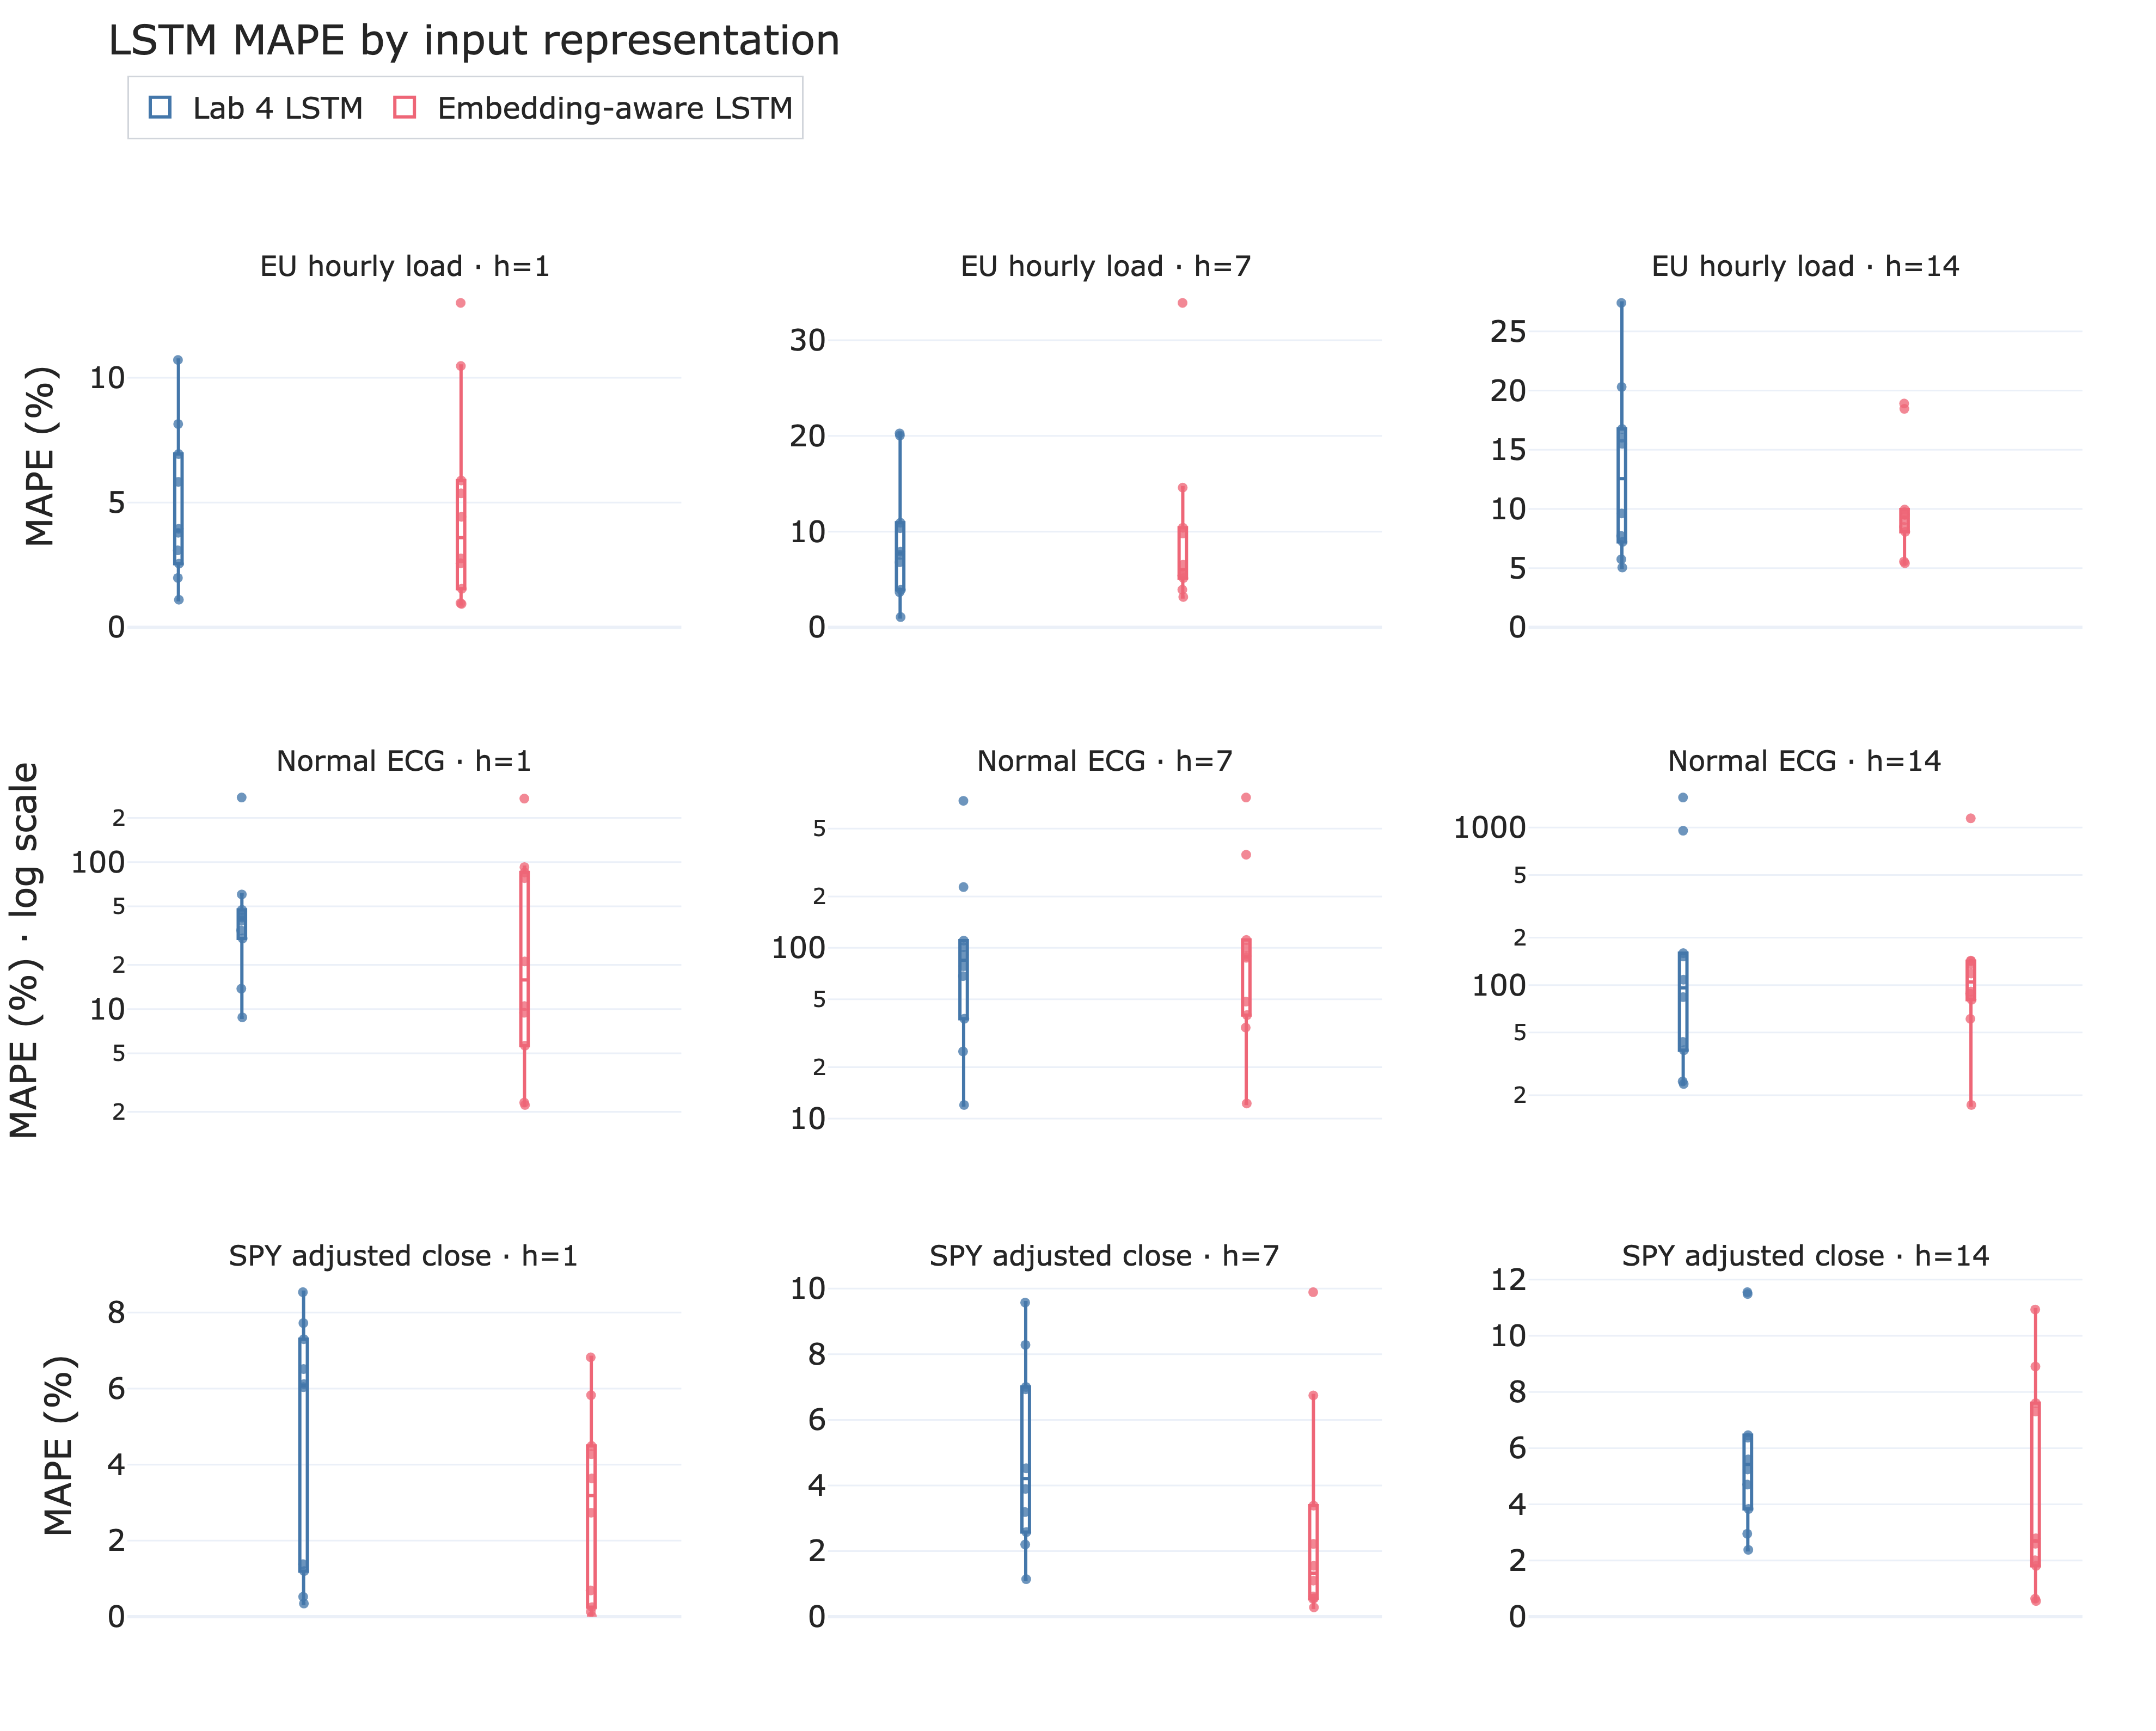

In [14]:
fig = make_subplots(
    rows=3, cols=3, horizontal_spacing=0.075, vertical_spacing=0.115,
    subplot_titles=tuple(
        f"{item.label} · h={horizon}"
        for item in series.values()
        for horizon in HORIZONS
    ),
)

for row, (key, item) in enumerate(series.items(), start=1):
    for col, horizon in enumerate(HORIZONS, start=1):
        subset = comparison_results[(comparison_results["series"] == key) & (comparison_results["horizon"] == horizon)]
        for model in ("Lab 4 LSTM", "Embedding-aware LSTM"):
            values = subset[subset["model"] == model]["mape"]
            fig.add_trace(
                go.Box(
                    y=values,
                    name=model,
                    boxpoints="all",
                    jitter=0.25,
                    pointpos=0,
                    marker=dict(color=METHOD_COLORS[model], size=6, opacity=0.78),
                    line=dict(color=METHOD_COLORS[model], width=2),
                    fillcolor="rgba(255,255,255,0.18)",
                    showlegend=row == 1 and col == 1,
                    legendgroup=model,
                    hovertemplate=f"{model}<br>MAPE=%{{y:.2f}}%<extra></extra>",
                ),
                row=row,
                col=col,
            )
        fig.update_xaxes(showticklabels=False, row=row, col=col)
        if row == 2:
            fig.update_yaxes(title_text="MAPE (%) · log scale" if col == 1 else None, type="log", row=row, col=col)
        else:
            fig.update_yaxes(title_text="MAPE (%)" if col == 1 else None, rangemode="tozero", row=row, col=col)

fig.update_layout(title="LSTM MAPE by input representation", boxmode="group")
show_and_save(
    fig, "lstm_mape_comparison",
    "Paired LSTM MAPE distributions by series and horizon",
    height=1060, top_margin=175, bottom_margin=70, legend_y=1.11,
)



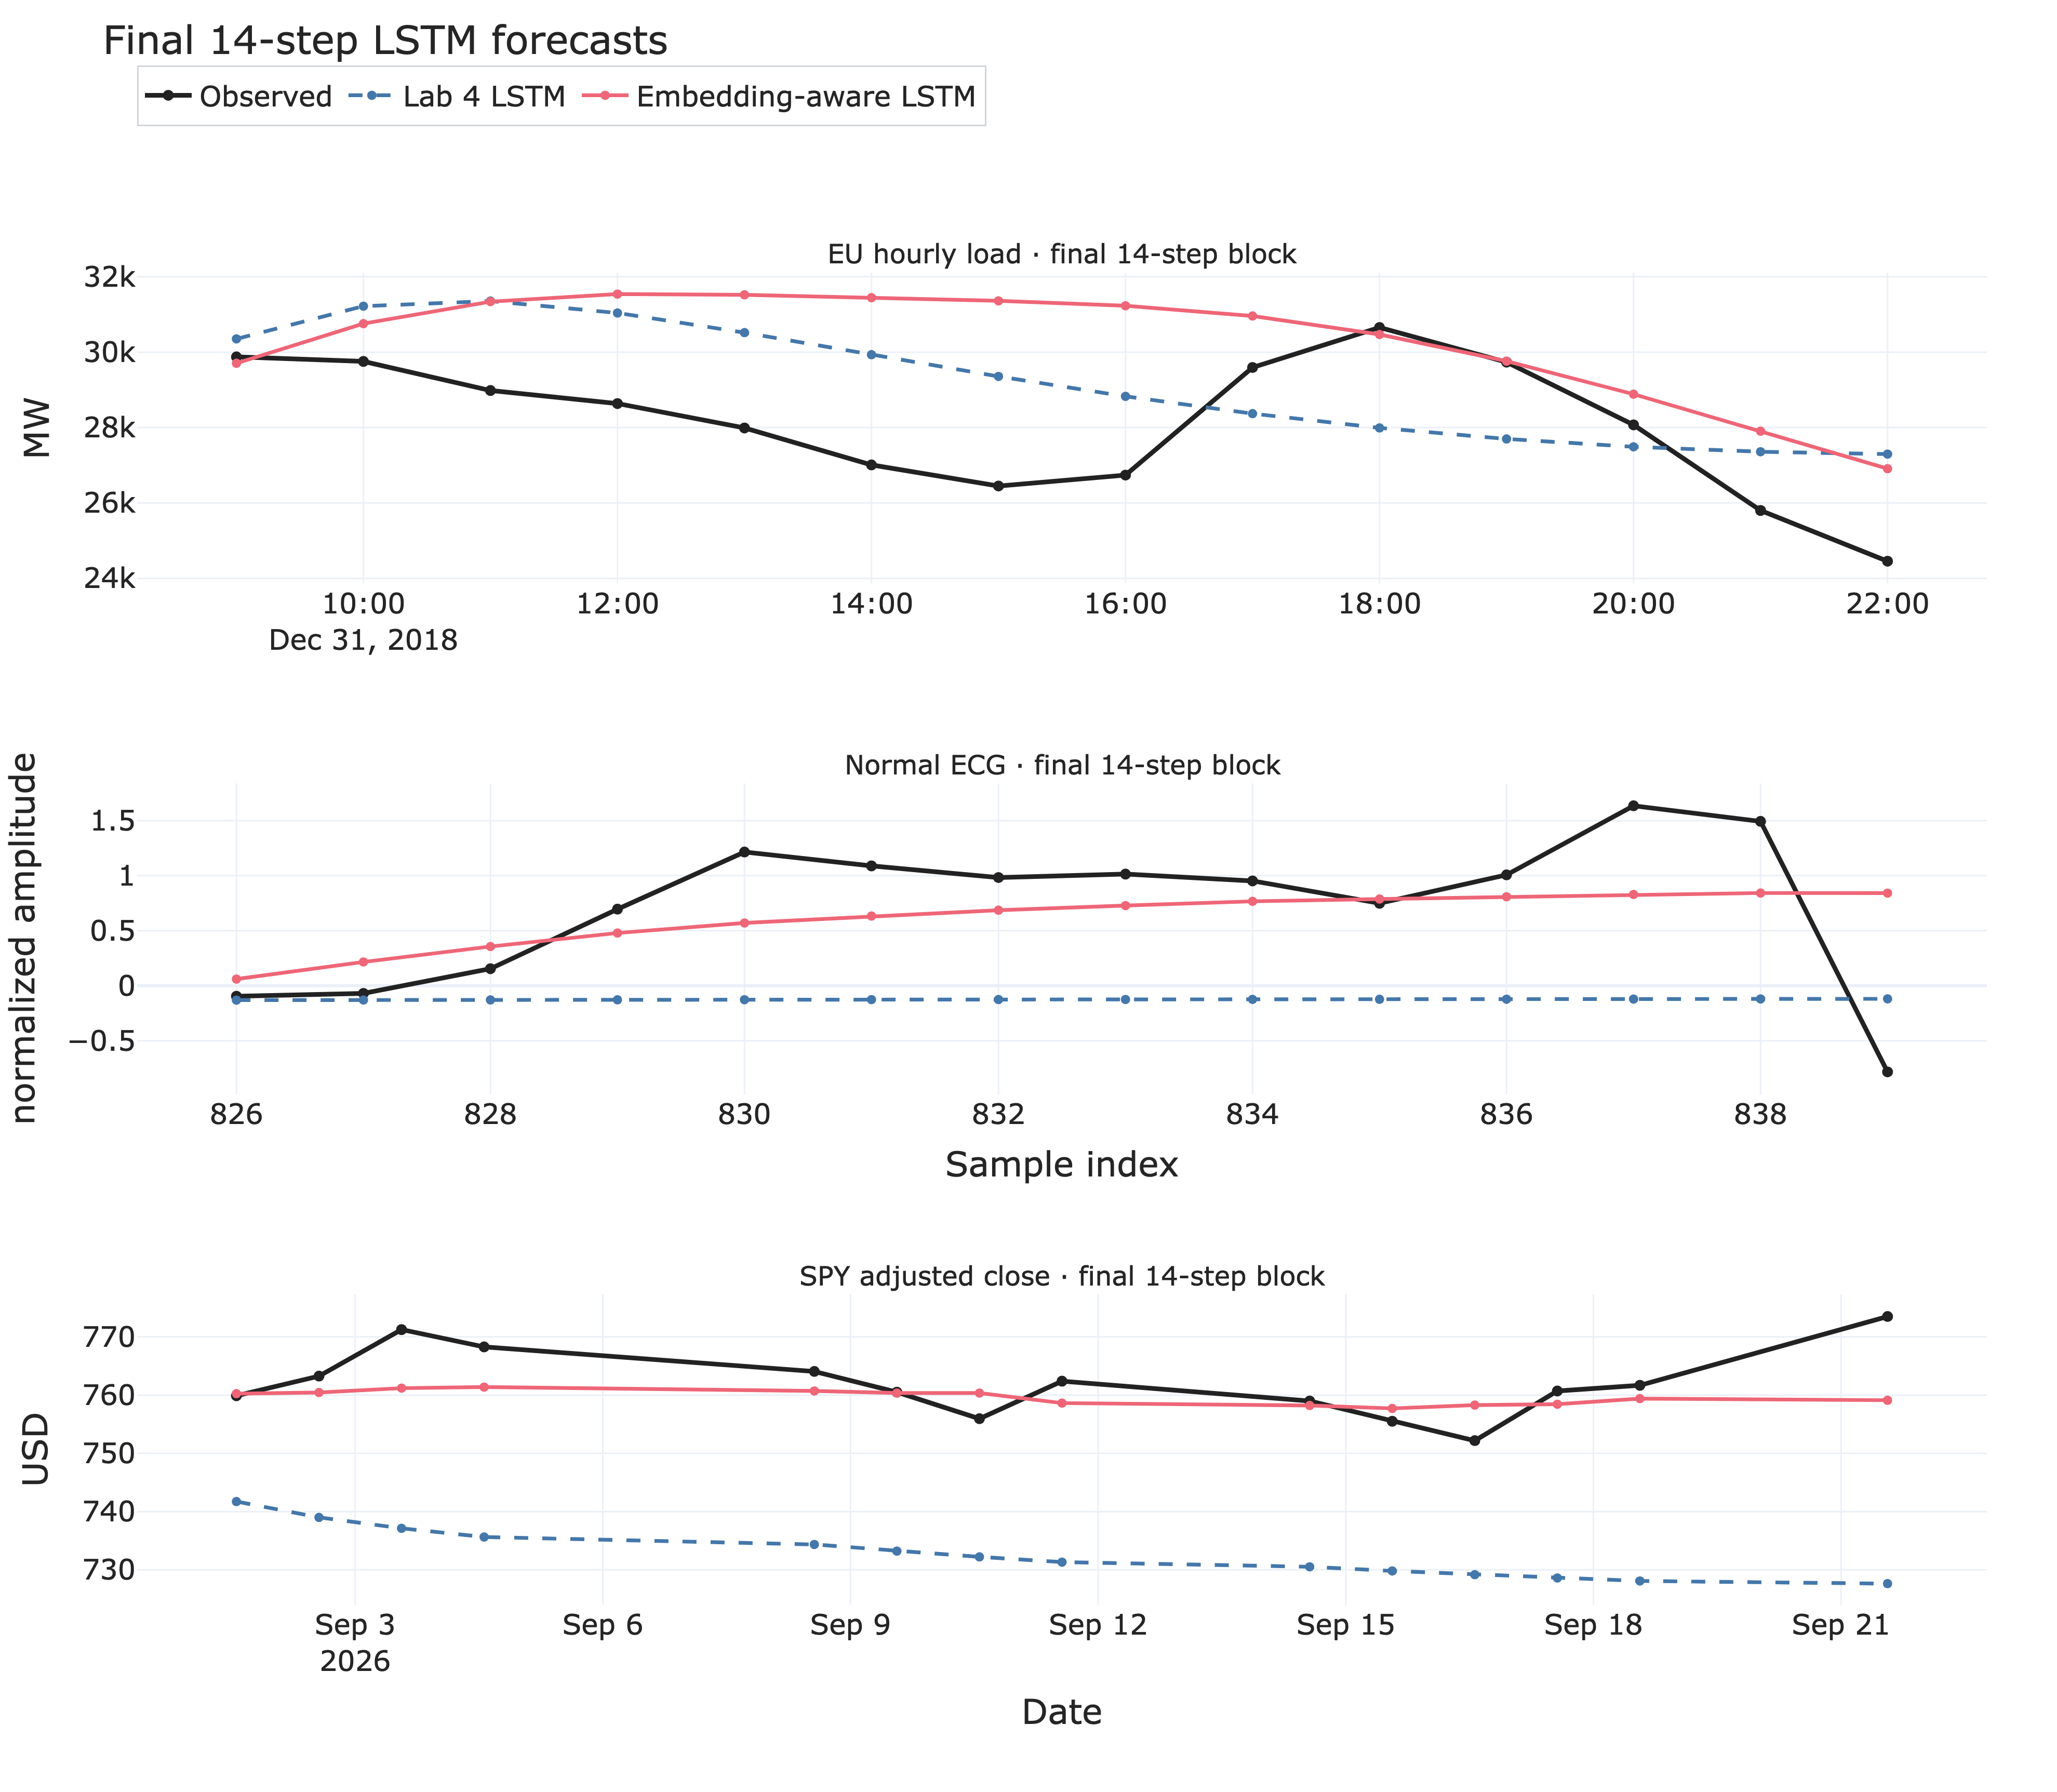

In [15]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.15,
    subplot_titles=tuple(f"{item.label} · final 14-step block" for item in series.values()),
)

for row, (key, item) in enumerate(series.items(), start=1):
    horizon, split = 14, 10
    origin = test_origins(len(item.values), horizon)[split - 1]
    x = item.index[origin:origin + horizon]
    actual = item.values[origin:origin + horizon]
    old = previous_paths[
        (previous_paths["series"] == key) & (previous_paths["horizon"] == horizon) & (previous_paths["split"] == split)
    ].sort_values("step")["predicted"].to_numpy()
    new = new_paths[
        (new_paths["series"] == key) & (new_paths["horizon"] == horizon) & (new_paths["split"] == split)
    ].sort_values("step")["predicted"].to_numpy()
    fig.add_trace(
        go.Scatter(
            x=x,
            y=actual,
            mode="lines+markers",
            name="Observed",
            line=dict(color="#222222", width=3),
            marker=dict(size=7),
            showlegend=row == 1,
            legendgroup="observed",
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=x,
            y=old,
            mode="lines+markers",
            name="Lab 4 LSTM",
            line=dict(color=METHOD_COLORS["Lab 4 LSTM"], width=2.4, dash="dash"),
            marker=dict(size=6),
            showlegend=row == 1,
            legendgroup="old",
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=x,
            y=new,
            mode="lines+markers",
            name="Embedding-aware LSTM",
            line=dict(color=METHOD_COLORS["Embedding-aware LSTM"], width=2.4),
            marker=dict(size=6),
            showlegend=row == 1,
            legendgroup="new",
        ),
        row=row,
        col=1,
    )
    fig.update_yaxes(title_text=item.unit, row=row, col=1)
    x_title = None if row == 1 else ("Sample index" if key == "ECG_TF_Normal" else "Date")
    fig.update_xaxes(title_text=x_title, row=row, col=1)

fig.update_layout(title="Final 14-step LSTM forecasts", hovermode="x unified")
show_and_save(
    fig, "lstm_final_block_paths",
    "Observed and LSTM forecast paths for final 14-step blocks",
    height=1150, top_margin=175, bottom_margin=120, legend_y=1.11,
)


### Forecast findings

Each MAPE box contains the same ten non-overlapping blocks as Lab 4; lower is better. The ECG row uses a logarithmic scale because near-zero targets inflate MAPE. The path figure is illustrative only, while the conclusions use all ten blocks.

For electricity load, mean MAPE is almost unchanged at one step (4.81% versus 4.79%), rises from 9.26% to 9.85% at seven steps, and falls from 13.14% to 10.32% at 14 steps. The reconstructed input wins 7, 5 and 6 of the ten paired blocks. Its seven-step median is lower (6.03% versus 7.74%), but the worst block is worse (33.90% versus 20.26%). The compact four-coordinate state is useful at the longest horizon in this experiment, while the mixed means and tails do not support a general improvement for load.

ECG mean MAPE changes from 59.68% to 57.75% at one step, from 147.89% to 163.57% at seven steps, and from 314.03% to 202.24% at 14 steps. The corresponding reconstructed-input medians are 15.79%, 88.56% and 104.70%, compared with 40.97%, 84.62% and 96.05% for Lab 4. The lower 14-step mean accompanies a higher median and a reduction of the worst block from 1551% to 1145%, so a few extreme errors still dominate it. MAE also improves slightly at one and 14 steps but worsens at seven steps. The reconstructed input wins 6, 3 and 6 blocks. These results show no consistent improvement across horizons, and neither illustrative forecast captures the sharp beat morphology.

SPY is the clearest numerical improvement in these matched-seed fits. Mean MAPE falls from 4.57%, 4.93% and 6.06% to 2.89%, 2.69% and 4.52% at horizons 1, 7 and 14, reductions of about 37%, 45% and 25%. The corresponding medians fall from 6.08%, 4.21% and 5.42% to 3.19%, 1.33% and 2.70%. The reconstructed input wins 8, 8 and 7 of ten blocks. Its final path stays near the recent price level while the Lab 4 forecast drifts downward. This supports the compact input for these samples, while additional seeds and periods would be needed to establish a stable advantage.


## 6. Conclusion

Delay reconstruction produces compact working representations for all three samples: $(\tau,m)=(6,4)$ for load, $(9,4)$ for ECG and $(7,3)$ for SPY, with selected-space correlation dimensions of 2.29, 1.77 and 1.62. These choices come from the development prefix, before the earliest test block. Because $D_2$ keeps rising with $m$ instead of settling onto a plateau, these values characterize the observed samples but do not establish their attractor dimensions.

The geometry is most interpretable when it agrees with known structure. Load revisits a moderately connected sequence of daily demand states; ECG repeatedly traverses a waveform loop but includes artificial segment-boundary transitions; SPY separates cleanly into nearly absorbing price-level states whose order follows calendar time. The transition statistics sharpen this contrast: persistence rises from 0.825 for load to 0.874 for ECG and 0.996 for SPY, while transition entropy falls from 0.297 to 0.222 and 0.019.

With initialization seeds matched, reconstructed inputs lower SPY mean and median MAPE at all three horizons. Load improves mainly at 14 steps, while ECG remains mixed and worsens at seven steps. These comparisons support a compact delayed input for some of the observed tasks, rather than a universal forecasting benefit. Matching starting weights makes the comparison more controlled, but one fit per block does not measure sensitivity to random initialization; broader claims require repeated seeds and additional test periods.

The main limitation is sample size: correlation slopes, t-SNE layouts, Ward states and neural forecasts are all estimated from fewer than one thousand observations. The analysis therefore treats reconstructed geometry as a comparative description of these samples, not as proof of an underlying attractor. For the concatenated ECG, segment boundaries are an additional artificial source of transitions; for SPY, non-stationarity and common market shocks remain more plausible explanations than autonomous low-dimensional dynamics.
